<a href="https://colab.research.google.com/github/HusnulAmira/ADW/blob/main/IHSG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Improt Library dan membaca data**

# New Section

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Membaca data Excel
df = pd.read_excel("/content/Data Jurnal benar.xlsx")

# Melihat 5 baris pertama
df.head()

,Tanggal,IHSG
0,2026-06-01,5643.19
1,2026-05-01,6127.38
2,2026-04-01,6956.80
3,2026-03-01,7048.22
4,2026-02-01,8235.49


**Cek Struktur Data**

In [ ]:
# Informasi struktur data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Tanggal  198 non-null    datetime64[ns]
 1   IHSG     198 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 3.2 KB


In [ ]:
# Melihat nama kolom
print(df.columns)

Index(['Tanggal', 'IHSG'], dtype='object')


In [ ]:
# Melihat jumlah baris dan kolom
print("Ukuran data:", df.shape)

Ukuran data: (198, 2)


**Pastikan kolom Tanggal menjadi format tanggal**

In [ ]:
df["Tanggal"] = pd.to_datetime(df["Tanggal"])

# Mengurutkan data dari tanggal paling lama ke paling baru
df = df.sort_values("Tanggal").reset_index(drop=True)

df.head()

,Tanggal,IHSG,Tahun
0,2010-01-01,2610.80,2010
1,2010-02-01,2549.03,2010
2,2010-03-01,2777.30,2010
3,2010-04-01,2971.25,2010
4,2010-05-01,2796.96,2010


**Cek periode dan jumlah observasi**

In [ ]:
print("Tanggal awal :", df["Tanggal"].min())
print("Tanggal akhir:", df["Tanggal"].max())
print("Jumlah observasi:", len(df))

Tanggal awal : 2010-01-01 00:00:00
Tanggal akhir: 2026-06-01 00:00:00
Jumlah observasi: 198


**Cek missing value**

In [ ]:
print("Missing value:")
print(df.isnull().sum())

Missing value:
Tanggal    0
IHSG       0
dtype: int64


**Cek data duplikat**

In [ ]:
print("Jumlah tanggal duplikat:",
      df["Tanggal"].duplicated().sum())

Jumlah tanggal duplikat: 0


**Statistik deskriptif IHSG**

In [ ]:
df["IHSG"].describe()

,IHSG
count,198.000000
mean,5586.337929
std,1319.602863
min,2549.030000
25%,4611.575000
50%,5711.725000
75%,6624.770000
max,8646.940000


In [ ]:
df["Tahun"] = df["Tanggal"].dt.year

tahunan = df.groupby("Tahun")["IHSG"].agg(
    ["mean", "min", "max"]
)

tahunan

,mean,min,max
Tahun,,,
2010,3095.126667,2549.03,3703.51
2011,3746.069167,3409.17,4130.80
2012,4118.827500,3832.82,4350.29
2013,4606.248333,4195.09,5068.63
2014,4937.460833,4418.76,5226.95
2015,4875.210000,4223.91,5518.67
2016,5059.885000,4615.16,5422.54
2017,5785.123333,5294.10,6355.65
2018,6098.582500,5799.24,6605.63


**Plot IHSG 2010–Juni 2026**

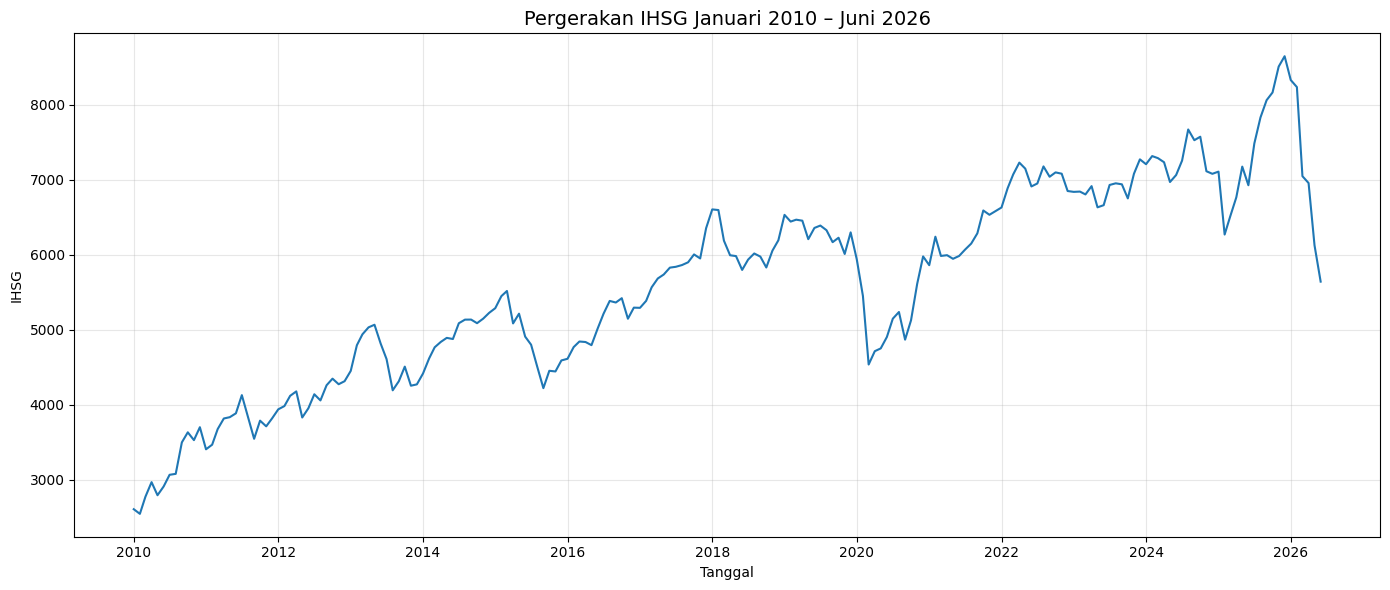

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Tanggal"],
    df["IHSG"],
    linewidth=1.5
)

plt.title("Pergerakan IHSG Januari 2010 – Juni 2026",
          fontsize=14)
plt.xlabel("Tanggal")
plt.ylabel("IHSG")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Identifikasi Tren**

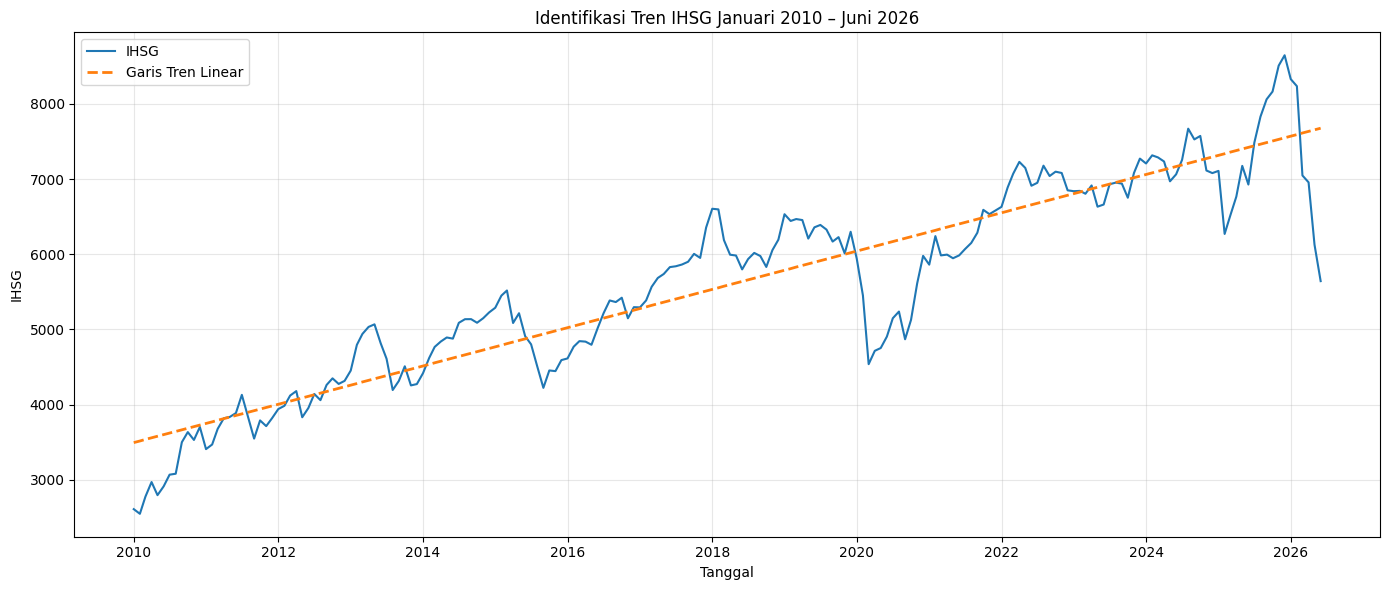

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Membuat indeks waktu
x = np.arange(len(df))
y = df["IHSG"].values

# Estimasi garis tren linear
koef = np.polyfit(x, y, 1)
trend = np.polyval(koef, x)

# Plot IHSG dan garis tren
plt.figure(figsize=(14, 6))

plt.plot(
    df["Tanggal"],
    df["IHSG"],
    label="IHSG",
    linewidth=1.5
)

plt.plot(
    df["Tanggal"],
    trend,
    linestyle="--",
    linewidth=2,
    label="Garis Tren Linear"
)

plt.title("Identifikasi Tren IHSG Januari 2010 – Juni 2026")
plt.xlabel("Tanggal")
plt.ylabel("IHSG")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Identifikasi Musiman**

<Figure size 1200x500 with 0 Axes>

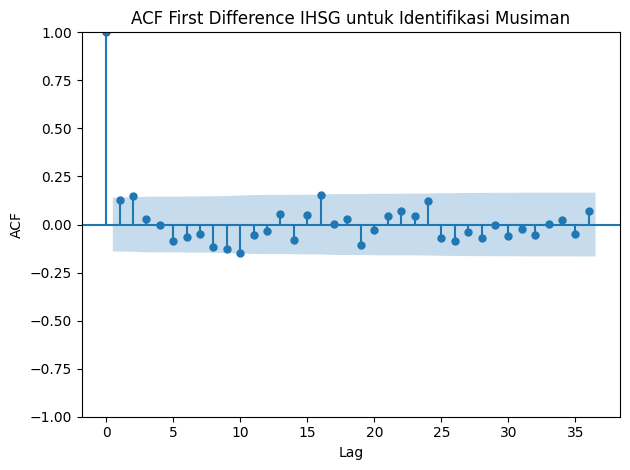

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(
    diff_ihsg,
    lags=36,
    alpha=0.05
)

plt.title("ACF First Difference IHSG untuk Identifikasi Musiman")
plt.xlabel("Lag")
plt.ylabel("ACF")

plt.tight_layout()
plt.show()

**Uji Stasioneritas**

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss

# Data IHSG
ihsg = df["IHSG"].dropna()

# =========================
# ADF TEST
# =========================
adf_result = adfuller(ihsg)

print("=== ADF TEST ===")
print(f"ADF Statistic : {adf_result[0]:.6f}")
print(f"p-value       : {adf_result[1]:.6f}")
print(f"Lag digunakan : {adf_result[2]}")
print(f"Observasi     : {adf_result[3]}")

if adf_result[1] < 0.05:
    print("Keputusan     : Stasioner")
else:
    print("Keputusan     : Tidak stasioner")


# =========================
# KPSS TEST
# =========================
kpss_result = kpss(
    ihsg,
    regression="c",
    nlags="auto"
)

print("\n=== KPSS TEST ===")
print(f"KPSS Statistic : {kpss_result[0]:.6f}")
print(f"p-value        : {kpss_result[1]:.6f}")
print(f"Lag digunakan  : {kpss_result[2]}")

if kpss_result[1] > 0.05:
    print("Keputusan      : Stasioner")
else:
    print("Keputusan      : Tidak stasioner")

=== ADF TEST ===
ADF Statistic : -2.414363
p-value       : 0.137724
Lag digunakan : 2
Observasi     : 195
Keputusan     : Tidak stasioner

=== KPSS TEST ===
KPSS Statistic : 1.866313
p-value        : 0.010000
Lag digunakan  : 9
Keputusan      : Tidak stasioner


/tmp/ipykernel_2281/815995613.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ihsg)
/tmp/ipykernel_2281/815995613.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_2281/815995613.py:26: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch no

**Differencing**

In [ ]:
# First differencing IHSG
df["Diff_IHSG"] = df["IHSG"].diff()

# Menghapus NA akibat differencing
diff_ihsg = df["Diff_IHSG"].dropna()

print(diff_ihsg.head())

1    -61.77
2    228.27
3    193.95
4   -174.29
5    116.72
Name: Diff_IHSG, dtype: float64


**Plot Differencing**

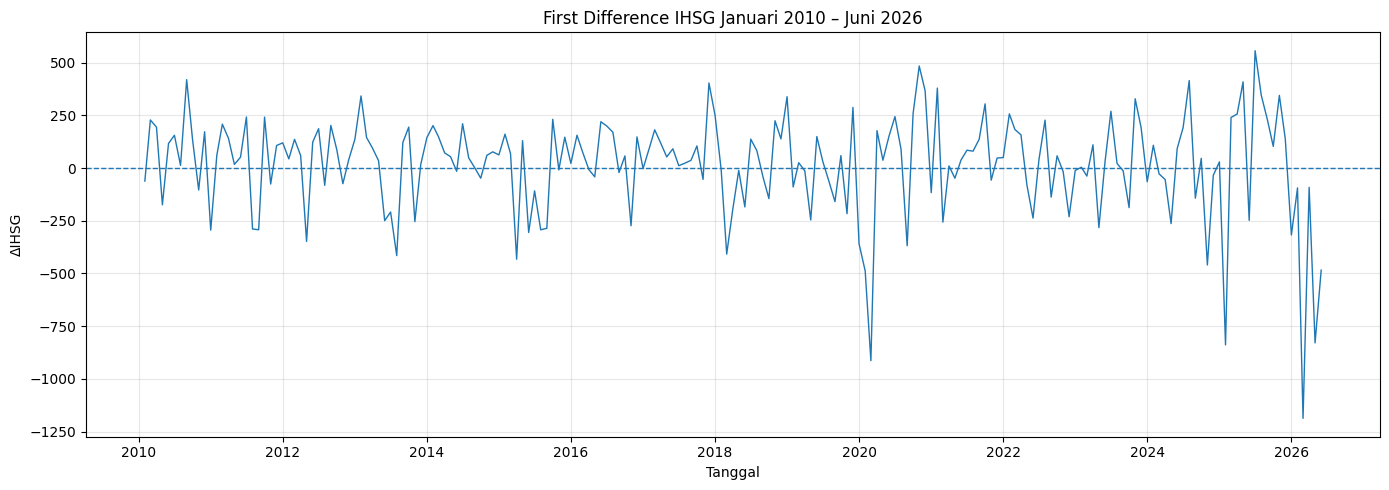

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Tanggal"].iloc[1:],
    diff_ihsg,
    linewidth=1
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("First Difference IHSG Januari 2010 – Juni 2026")
plt.xlabel("Tanggal")
plt.ylabel("ΔIHSG")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**ADF & KPSS**

In [ ]:
# =========================
# ADF TEST - FIRST DIFFERENCE
# =========================
adf_diff = adfuller(diff_ihsg)

print("=== ADF TEST - FIRST DIFFERENCE ===")
print(f"ADF Statistic : {adf_diff[0]:.6f}")
print(f"p-value       : {adf_diff[1]:.6f}")
print(f"Lag digunakan : {adf_diff[2]}")
print(f"Observasi     : {adf_diff[3]}")

if adf_diff[1] < 0.05:
    print("Keputusan     : Stasioner")
else:
    print("Keputusan     : Tidak stasioner")


# =========================
# KPSS TEST - FIRST DIFFERENCE
# =========================
kpss_diff = kpss(
    diff_ihsg,
    regression="c",
    nlags="auto"
)

print("\n=== KPSS TEST - FIRST DIFFERENCE ===")
print(f"KPSS Statistic : {kpss_diff[0]:.6f}")
print(f"p-value        : {kpss_diff[1]:.6f}")
print(f"Lag digunakan  : {kpss_diff[2]}")

if kpss_diff[1] > 0.05:
    print("Keputusan      : Stasioner")
else:
    print("Keputusan      : Tidak stasioner")

=== ADF TEST - FIRST DIFFERENCE ===
ADF Statistic : -7.446258
p-value       : 0.000000
Lag digunakan : 1
Observasi     : 195
Keputusan     : Stasioner

=== KPSS TEST - FIRST DIFFERENCE ===
KPSS Statistic : 0.159011
p-value        : 0.100000
Lag digunakan  : 4
Keputusan      : Stasioner


/tmp/ipykernel_2281/3317995674.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(diff_ihsg)
/tmp/ipykernel_2281/3317995674.py:21: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff = kpss(
/tmp/ipykernel_2281/3317995674.py:21: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switc

**Mengidentifikasi Musiman**

<Figure size 1400x500 with 0 Axes>

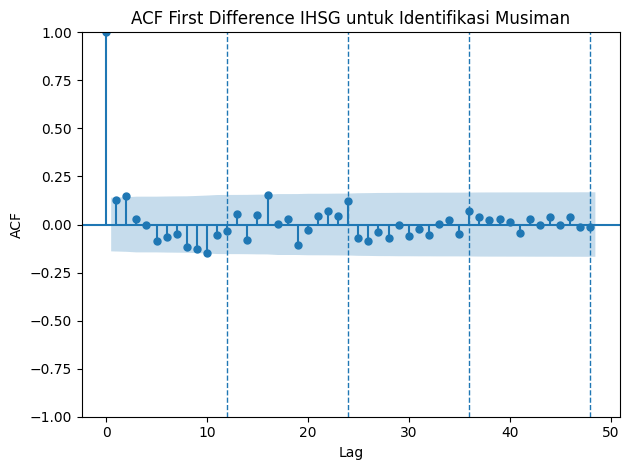

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plot_acf(
    diff_ihsg,
    lags=48,
    alpha=0.05
)

plt.axvline(
    12,
    linestyle="--",
    linewidth=1
)

plt.axvline(
    24,
    linestyle="--",
    linewidth=1
)

plt.axvline(
    36,
    linestyle="--",
    linewidth=1
)

plt.axvline(
    48,
    linestyle="--",
    linewidth=1
)

plt.title("ACF First Difference IHSG untuk Identifikasi Musiman")
plt.xlabel("Lag")
plt.ylabel("ACF")

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import acf

acf_values, confint = acf(
    diff_ihsg,
    nlags=48,
    alpha=0.05
)

for lag in [12, 24, 36, 48]:
    print(f"\nLag {lag}")
    print(f"ACF       : {acf_values[lag]:.6f}")
    print(f"CI bawah  : {confint[lag, 0]:.6f}")
    print(f"CI atas   : {confint[lag, 1]:.6f}")

    if confint[lag, 0] > 0 or confint[lag, 1] < 0:
        print("Keputusan : SIGNIFIKAN (ada spike)")
    else:
        print("Keputusan : TIDAK SIGNIFIKAN")


Lag 12
ACF       : -0.031492
CI bawah  : -0.185406
CI atas   : 0.122421
Keputusan : TIDAK SIGNIFIKAN

Lag 24
ACF       : 0.121147
CI bawah  : -0.039942
CI atas   : 0.282235
Keputusan : TIDAK SIGNIFIKAN

Lag 36
ACF       : 0.070592
CI bawah  : -0.095630
CI atas   : 0.236814
Keputusan : TIDAK SIGNIFIKAN

Lag 48
ACF       : -0.010728
CI bawah  : -0.178606
CI atas   : 0.157149
Keputusan : TIDAK SIGNIFIKAN


/tmp/ipykernel_2281/1554171351.py:3: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, confint = acf(


**ACF dan PACF**

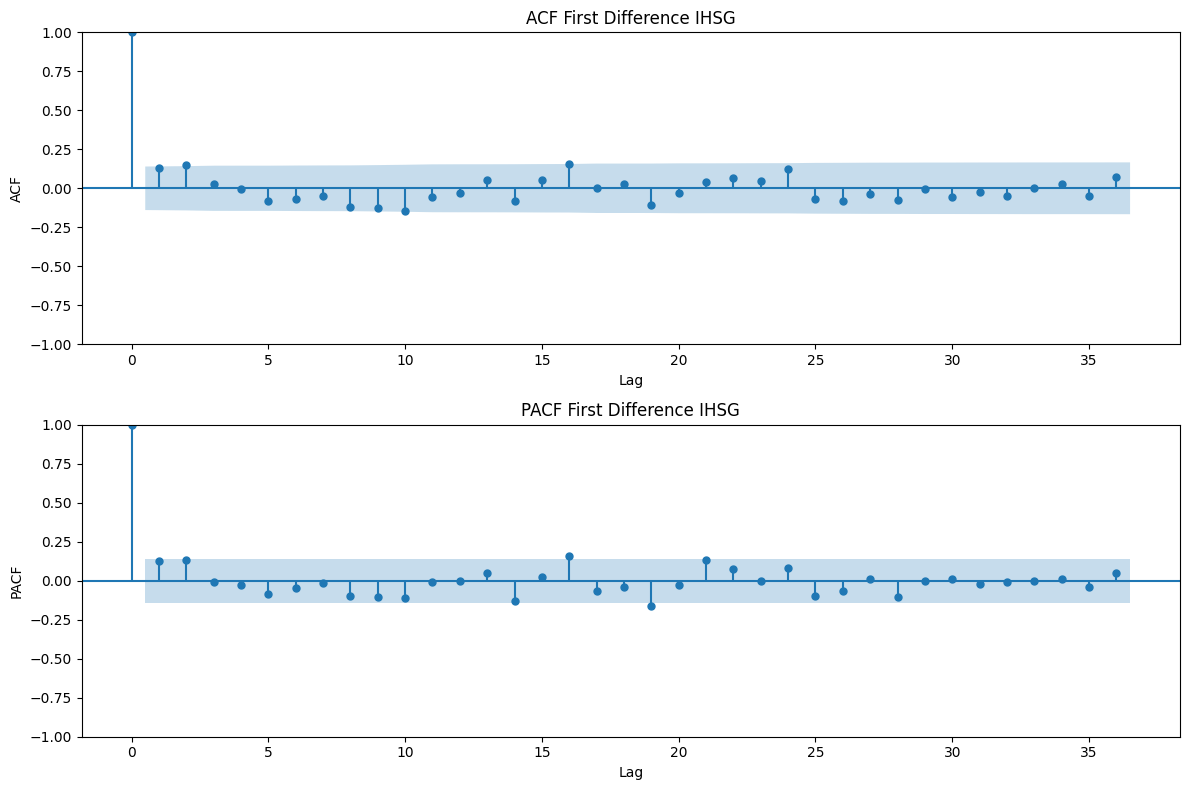

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# ACF
plot_acf(
    diff_ihsg,
    lags=36,
    alpha=0.05,
    ax=ax[0]
)

ax[0].set_title("ACF First Difference IHSG")
ax[0].set_xlabel("Lag")
ax[0].set_ylabel("ACF")

# PACF
plot_pacf(
    diff_ihsg,
    lags=36,
    alpha=0.05,
    method="ywm",
    ax=ax[1]
)

ax[1].set_title("PACF First Difference IHSG")
ax[1].set_xlabel("Lag")
ax[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

**PEMODELAN**

Training Testing

In [ ]:
n = len(df)

n_train = int(n * 0.80)

train = df.iloc[:n_train].copy()
test = df.iloc[n_train:].copy()

print("Jumlah data keseluruhan :", len(df))
print("Jumlah data training   :", len(train))
print("Jumlah data testing    :", len(test))

print("\nPeriode Training:")
print(train["Tanggal"].min(), "sampai", train["Tanggal"].max())

print("\nPeriode Testing:")
print(test["Tanggal"].min(), "sampai", test["Tanggal"].max())

Jumlah data keseluruhan : 198
Jumlah data training   : 158
Jumlah data testing    : 40

Periode Training:
2010-01-01 00:00:00 sampai 2023-02-01 00:00:00

Periode Testing:
2023-03-01 00:00:00 sampai 2026-06-01 00:00:00


**Plot Training Testing**

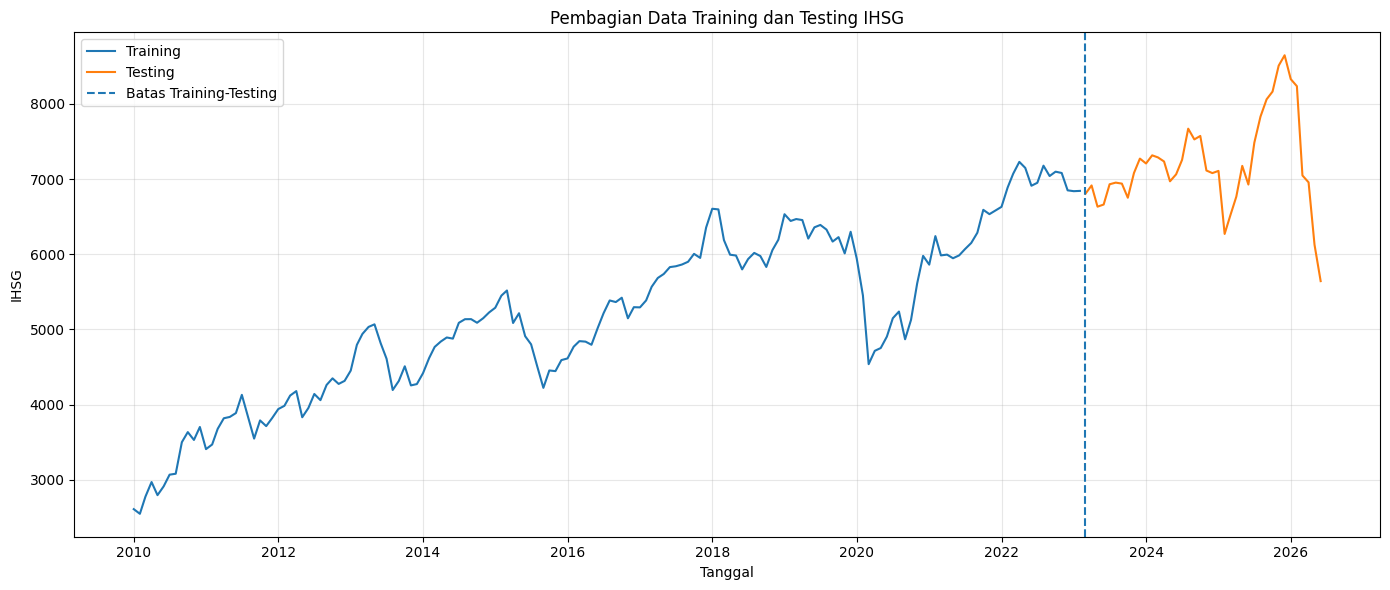

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    train["Tanggal"],
    train["IHSG"],
    label="Training"
)

plt.plot(
    test["Tanggal"],
    test["IHSG"],
    label="Testing"
)

plt.axvline(
    test["Tanggal"].iloc[0],
    linestyle="--",
    label="Batas Training-Testing"
)

plt.title("Pembagian Data Training dan Testing IHSG")
plt.xlabel("Tanggal")
plt.ylabel("IHSG")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
ihsg_train = train["IHSG"].copy()
ihsg_test = test["IHSG"].copy()

**Uji Stasioneritas Training**

**ADF**

In [ ]:
adf_train = adfuller(ihsg_train)

print("=== ADF TEST - TRAINING ===")
print(f"ADF Statistic : {adf_train[0]:.6f}")
print(f"p-value       : {adf_train[1]:.6f}")
print(f"Lag digunakan : {adf_train[2]}")
print(f"Observasi     : {adf_train[3]}")

if adf_train[1] < 0.05:
    print("Keputusan     : Stasioner")
else:
    print("Keputusan     : Tidak stasioner")

=== ADF TEST - TRAINING ===
ADF Statistic : -1.989048
p-value       : 0.291396
Lag digunakan : 1
Observasi     : 156
Keputusan     : Tidak stasioner


/tmp/ipykernel_2281/686710403.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_train = adfuller(ihsg_train)


**KPSS**

In [ ]:
kpss_train = kpss(
    ihsg_train,
    regression="c",
    nlags="auto"
)

print("\n=== KPSS TEST - TRAINING ===")
print(f"KPSS Statistic : {kpss_train[0]:.6f}")
print(f"p-value        : {kpss_train[1]:.6f}")
print(f"Lag digunakan  : {kpss_train[2]}")

if kpss_train[1] > 0.05:
    print("Keputusan      : Stasioner")
else:
    print("Keputusan      : Tidak stasioner")


=== KPSS TEST - TRAINING ===
KPSS Statistic : 1.598374
p-value        : 0.010000
Lag digunakan  : 8
Keputusan      : Tidak stasioner


/tmp/ipykernel_2281/3845804602.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_train = kpss(
/tmp/ipykernel_2281/3845804602.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_train = kpss(


**Differencing 1**

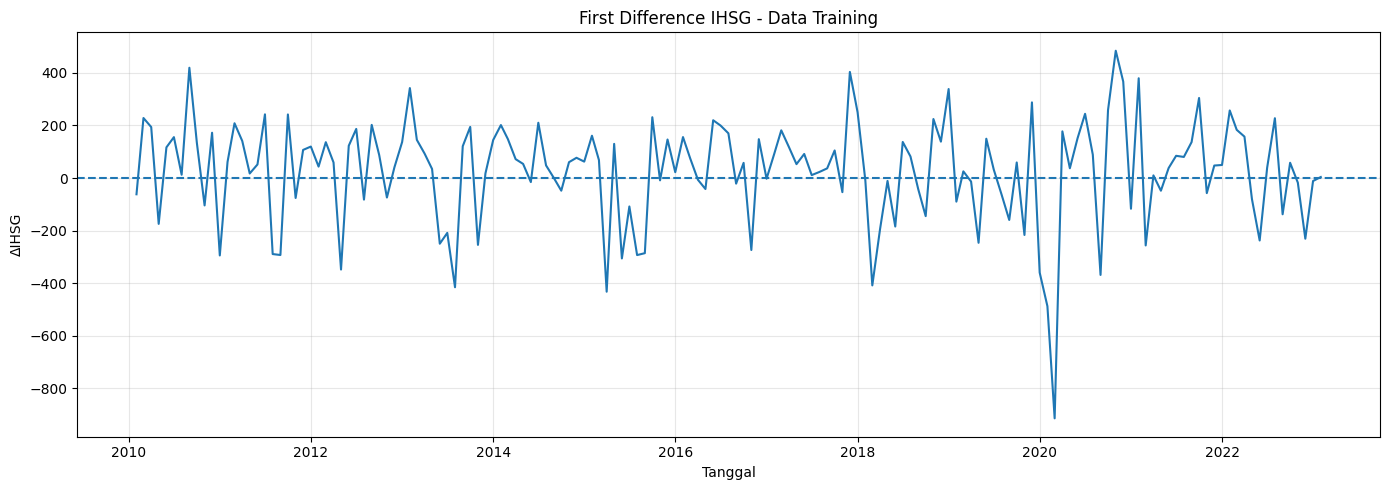

In [ ]:
diff_train = ihsg_train.diff().dropna()

plt.figure(figsize=(14, 5))

plt.plot(
    train["Tanggal"].iloc[1:],
    diff_train
)

plt.axhline(0, linestyle="--")

plt.title("First Difference IHSG - Data Training")
plt.xlabel("Tanggal")
plt.ylabel("ΔIHSG")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**ADF Differencing**

In [ ]:
adf_diff_train = adfuller(diff_train)

print("=== ADF TEST - FIRST DIFFERENCE TRAINING ===")
print(f"ADF Statistic : {adf_diff_train[0]:.6f}")
print(f"p-value       : {adf_diff_train[1]:.6f}")
print(f"Lag digunakan : {adf_diff_train[2]}")
print(f"Observasi     : {adf_diff_train[3]}")

if adf_diff_train[1] < 0.05:
    print("Keputusan     : Stasioner")
else:
    print("Keputusan     : Tidak stasioner")

=== ADF TEST - FIRST DIFFERENCE TRAINING ===
ADF Statistic : -11.140668
p-value       : 0.000000
Lag digunakan : 0
Observasi     : 156
Keputusan     : Stasioner


/tmp/ipykernel_2281/3302240500.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_train = adfuller(diff_train)


**KPSS Differencing**

In [ ]:
kpss_diff_train = kpss(
    diff_train,
    regression="c",
    nlags="auto"
)

print("\n=== KPSS TEST - FIRST DIFFERENCE TRAINING ===")
print(f"KPSS Statistic : {kpss_diff_train[0]:.6f}")
print(f"p-value        : {kpss_diff_train[1]:.6f}")
print(f"Lag digunakan  : {kpss_diff_train[2]}")

if kpss_diff_train[1] > 0.05:
    print("Keputusan      : Stasioner")
else:
    print("Keputusan      : Tidak stasioner")


=== KPSS TEST - FIRST DIFFERENCE TRAINING ===
KPSS Statistic : 0.079011
p-value        : 0.100000
Lag digunakan  : 0
Keputusan      : Stasioner


/tmp/ipykernel_2281/1521290423.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff_train = kpss(
/tmp/ipykernel_2281/1521290423.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_diff_train = kpss(


**Pemeriksaan Seasonality**

In [ ]:
acf_values, confint = acf(
    diff_train,
    nlags=48,
    alpha=0.05
)

for lag in [12, 24, 36, 48]:

    print(f"\nLag {lag}")
    print(f"ACF       : {acf_values[lag]:.6f}")
    print(f"CI bawah  : {confint[lag, 0]:.6f}")
    print(f"CI atas   : {confint[lag, 1]:.6f}")

    if confint[lag, 0] > 0 or confint[lag, 1] < 0:
        print("Keputusan : SIGNIFIKAN")
    else:
        print("Keputusan : TIDAK SIGNIFIKAN")


Lag 12
ACF       : 0.047011
CI bawah  : -0.122781
CI atas   : 0.216804
Keputusan : TIDAK SIGNIFIKAN

Lag 24
ACF       : 0.132552
CI bawah  : -0.043646
CI atas   : 0.308750
Keputusan : TIDAK SIGNIFIKAN

Lag 36
ACF       : 0.024398
CI bawah  : -0.164889
CI atas   : 0.213685
Keputusan : TIDAK SIGNIFIKAN

Lag 48
ACF       : 0.041882
CI bawah  : -0.149895
CI atas   : 0.233659
Keputusan : TIDAK SIGNIFIKAN


/tmp/ipykernel_2281/2850590037.py:1: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, confint = acf(


**ACF**

<Figure size 1200x500 with 0 Axes>

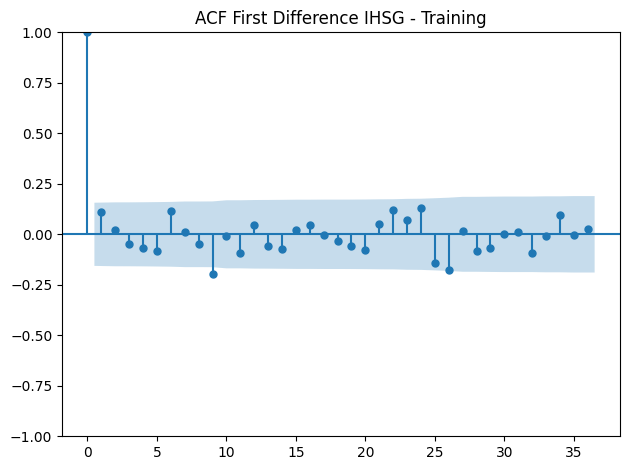

In [ ]:
plt.figure(figsize=(12, 5))

plot_acf(
    diff_train,
    lags=36,
    alpha=0.05
)

plt.title("ACF First Difference IHSG - Training")
plt.tight_layout()
plt.show()

**PACF**

<Figure size 1200x500 with 0 Axes>

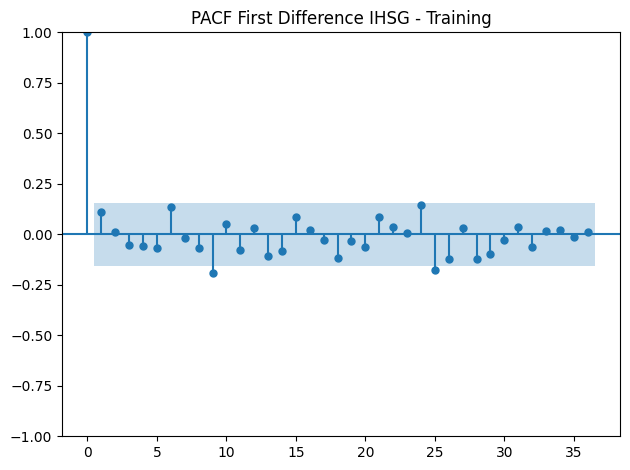

In [ ]:
plt.figure(figsize=(12, 5))

plot_pacf(
    diff_train,
    lags=36,
    alpha=0.05,
    method="ywm"
)

plt.title("PACF First Difference IHSG - Training")
plt.tight_layout()
plt.show()

**Estimasi ARIMA**

In [ ]:
candidates = [
    (0, 1, 1),
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

results = []

for order in candidates:

    try:

        model = ARIMA(
            ihsg_train,
            order=order
        )

        fitted = model.fit()

        results.append({
            "Model": f"ARIMA{order}",
            "AIC": fitted.aic,
            "BIC": fitted.bic
        })

    except Exception as e:
        print(f"ARIMA{order} gagal: {e}")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("AIC")

results_df

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Model,AIC,BIC
7,"ARIMA(2, 1, 2)",2110.224926,2125.506155
1,"ARIMA(1, 1, 0)",2110.895627,2117.008118
0,"ARIMA(0, 1, 1)",2111.072390,2117.184881
4,"ARIMA(0, 1, 2)",2112.664727,2121.833465
3,"ARIMA(2, 1, 0)",2112.762133,2121.930871
5,"ARIMA(2, 1, 1)",2112.800165,2125.025148
2,"ARIMA(1, 1, 1)",2112.819987,2121.988725
6,"ARIMA(1, 1, 2)",2114.660631,2126.885614


In [ ]:
# Kandidat yang akan diperiksa
candidate_orders = [
    (2, 1, 2),
    (1, 1, 0),
    (0, 1, 1)
]

diagnostic_results = []

for order in candidate_orders:

    model = ARIMA(
        ihsg_train,
        order=order
    )

    fitted = model.fit()

    residual = fitted.resid.dropna()

    # Ljung-Box
    lb = acorr_ljungbox(
        residual,
        lags=[12, 24],
        return_df=True
    )

    # ARCH-LM
    arch = het_arch(
        residual,
        nlags=12
    )

    diagnostic_results.append({
        "Model": f"ARIMA{order}",
        "AIC": fitted.aic,
        "BIC": fitted.bic,
        "LB_pvalue_12": lb.loc[12, "lb_pvalue"],
        "LB_pvalue_24": lb.loc[24, "lb_pvalue"],
        "ARCH_LM_pvalue": arch[1]
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

diagnostic_df

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set re

,Model,AIC,BIC,LB_pvalue_12,LB_pvalue_24,ARCH_LM_pvalue
0,"ARIMA(2, 1, 2)",2110.224926,2125.506155,0.995230,0.998593,0.057600
1,"ARIMA(1, 1, 0)",2110.895627,2117.008118,0.963917,0.987797,0.144014
2,"ARIMA(0, 1, 1)",2111.072390,2117.184881,0.962867,0.988172,0.181385


In [ ]:
candidate_orders = [
    (2, 1, 2),
    (1, 1, 0),
    (0, 1, 1)
]

for order in candidate_orders:

    model = ARIMA(
        ihsg_train,
        order=order
    )

    fitted = model.fit()

    print("=" * 60)
    print(f"ARIMA{order}")
    print("=" * 60)
    print(fitted.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA(2, 1, 2)
                               SARIMAX Results                                
Dep. Variable:                   IHSG   No. Observations:                  158
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1050.112
Date:                Thu, 24 Sep 2026   AIC                           2110.225
Time:                        16:44:50   BIC                           2125.506
Sample:                             0   HQIC                          2116.431
                                - 158                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6542      0.125      5.227      0.000       0.409       0.899
ar.L2         -0.8428      0.101     -8.370      0.000      -1.040      -0.645
ma.L1         -0.5535      0.116     

**Estimasi Model ARIMA**

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd

# Data IHSG level
ihsg = df["IHSG"].dropna()

# Kandidat model
orders = [
    (0,1,1),
    (1,1,0),
    (1,1,1),
    (2,1,0),
    (0,1,2),
    (2,1,1),
    (1,1,2)
]

hasil = []

for order in orders:
    model = ARIMA(ihsg, order=order).fit()

    hasil.append({
        "Model": f"ARIMA{order}",
        "AIC": model.aic,
        "BIC": model.bic
    })

hasil_model = pd.DataFrame(hasil)

hasil_model.sort_values("AIC")

,Model,AIC,BIC
3,"ARIMA(2, 1, 0)",2715.772009,2725.621620
4,"ARIMA(0, 1, 2)",2716.352526,2726.202138
6,"ARIMA(1, 1, 2)",2717.676176,2730.808991
2,"ARIMA(1, 1, 1)",2717.736470,2727.586081
5,"ARIMA(2, 1, 1)",2717.773694,2730.906509
1,"ARIMA(1, 1, 0)",2718.211505,2724.777912
0,"ARIMA(0, 1, 1)",2719.043175,2725.609582


In [ ]:
model_210 = ARIMA(
    ihsg,
    order=(2,1,0)
).fit()

print(model_210.summary())

                               SARIMAX Results                                
Dep. Variable:                   IHSG   No. Observations:                  198
Model:                 ARIMA(2, 1, 0)   Log Likelihood               -1354.886
Date:                Thu, 24 Sep 2026   AIC                           2715.772
Time:                        14:49:09   BIC                           2725.622
Sample:                             0   HQIC                          2719.759
                                - 198                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1192      0.064      1.868      0.062      -0.006       0.244
ar.L2          0.1546      0.054      2.855      0.004       0.048       0.261
sigma2       5.54e+04   3993.302     13.874      0.0

**Ljung-Box**

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

resid_210 = model_210.resid

ljung_210 = acorr_ljungbox(
    resid_210,
    lags=[12, 24],
    return_df=True
)

print(ljung_210)

      lb_stat  lb_pvalue
12   4.044236   0.982625
24  15.764144   0.896400


In [ ]:
from statsmodels.stats.diagnostic import het_arch

arch_210 = het_arch(resid_210)

print("LM Statistic :", arch_210[0])
print("LM p-value   :", arch_210[1])

LM Statistic : 20.097287148778868
LM p-value   : 0.02834582784321162


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


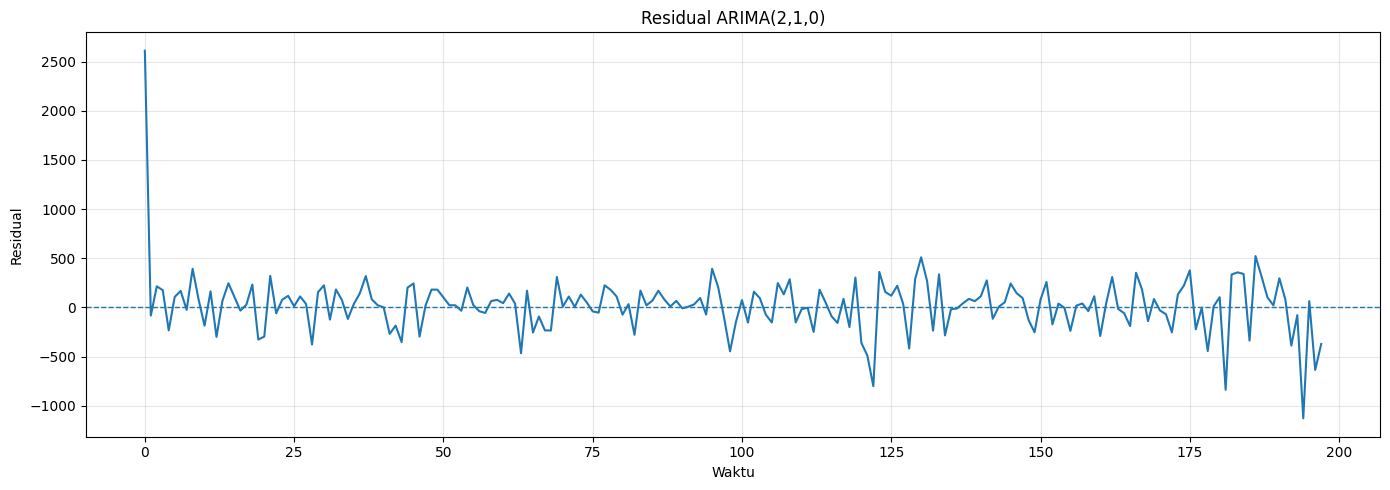

In [ ]:
plt.figure(figsize=(14,5))

plt.plot(resid_210)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Residual ARIMA(2,1,0)")
plt.xlabel("Waktu")
plt.ylabel("Residual")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

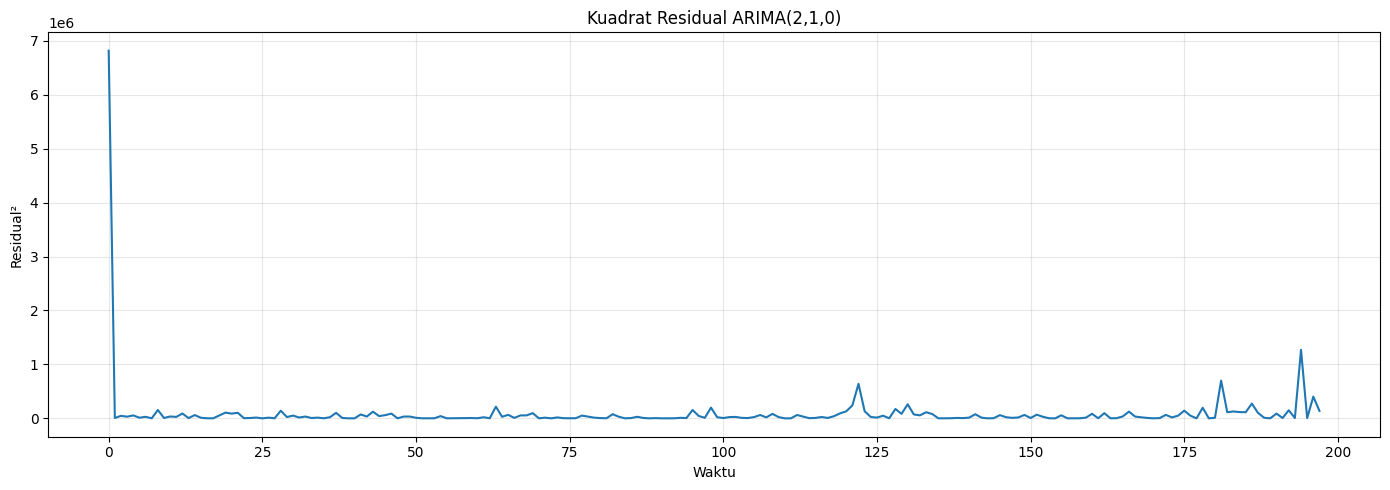

In [ ]:
squared_resid_210 = resid_210 ** 2

plt.figure(figsize=(14,5))

plt.plot(squared_resid_210)

plt.title("Kuadrat Residual ARIMA(2,1,0)")
plt.xlabel("Waktu")
plt.ylabel("Residual²")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

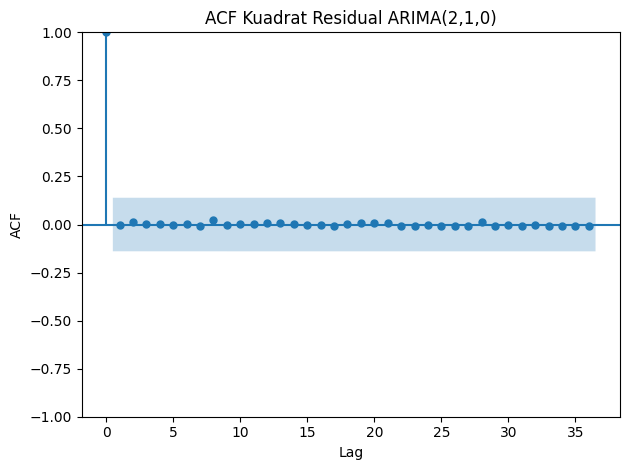

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12,5))

plot_acf(
    squared_resid_210,
    lags=36,
    alpha=0.05
)

plt.title("ACF Kuadrat Residual ARIMA(2,1,0)")
plt.xlabel("Lag")
plt.ylabel("ACF")

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.stats.stattools import jarque_bera

jb_result = jarque_bera(resid_210)

print("Jarque-Bera Statistic :", jb_result[0])
print("p-value               :", jb_result[1])

Jarque-Bera Statistic : 6805.87245016909
p-value               : 0.0


## **EKSPLORASI DATA**

- Membaca Data

In [2]:
# Instalasi library jika diperlukan
!pip install openpyxl statsmodels -q

# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

# Upload file Excel
from google.colab import files
uploaded = files.upload()

# Membaca data
df = pd.read_excel("/content/Data Jurnal benar.xlsx")
df

Saving Data Jurnal benar.xlsx to Data Jurnal benar (1).xlsx


,Tanggal,IHSG
0,2026-06-01,5643.19
1,2026-05-01,6127.38
2,2026-04-01,6956.80
3,2026-03-01,7048.22
4,2026-02-01,8235.49
...,...,...
193,2010-05-01,2796.96
194,2010-04-01,2971.25
195,2010-03-01,2777.30
196,2010-02-01,2549.03


In [3]:
# Mengubah kolom tanggal menjadi format datetime
df["Tanggal"] = pd.to_datetime(df["Tanggal"])

# Mengurutkan data dari tanggal terlama
df = df.sort_values("Tanggal").reset_index(drop=True)

# Menjadikan tanggal sebagai indeks
df = df.set_index("Tanggal")

# Menampilkan data
display(df.head())
display(df.tail())

,IHSG
Tanggal,
2010-01-01,2610.80
2010-02-01,2549.03
2010-03-01,2777.30
2010-04-01,2971.25
2010-05-01,2796.96


,IHSG
Tanggal,
2026-02-01,8235.49
2026-03-01,7048.22
2026-04-01,6956.80
2026-05-01,6127.38
2026-06-01,5643.19


- Memeriksa Kualitas Data

In [4]:
# Informasi data
print("Dimensi data:", df.shape)
print("\nTipe data:")
print(df.dtypes)

# Pemeriksaan nilai kosong
print("\nNilai kosong:")
print(df.isnull().sum())

# Pemeriksaan tanggal duplikat
print("\nJumlah tanggal duplikat:",
      df.index.duplicated().sum())

# Statistik deskriptif
display(df["IHSG"].describe())

Dimensi data: (198, 1)

Tipe data:
IHSG    float64
dtype: object

Nilai kosong:
IHSG    0
dtype: int64

Jumlah tanggal duplikat: 0


,IHSG
count,198.000000
mean,5586.337929
std,1319.602863
min,2549.030000
25%,4611.575000
50%,5711.725000
75%,6624.770000
max,8646.940000


- Plot Deret Waktu

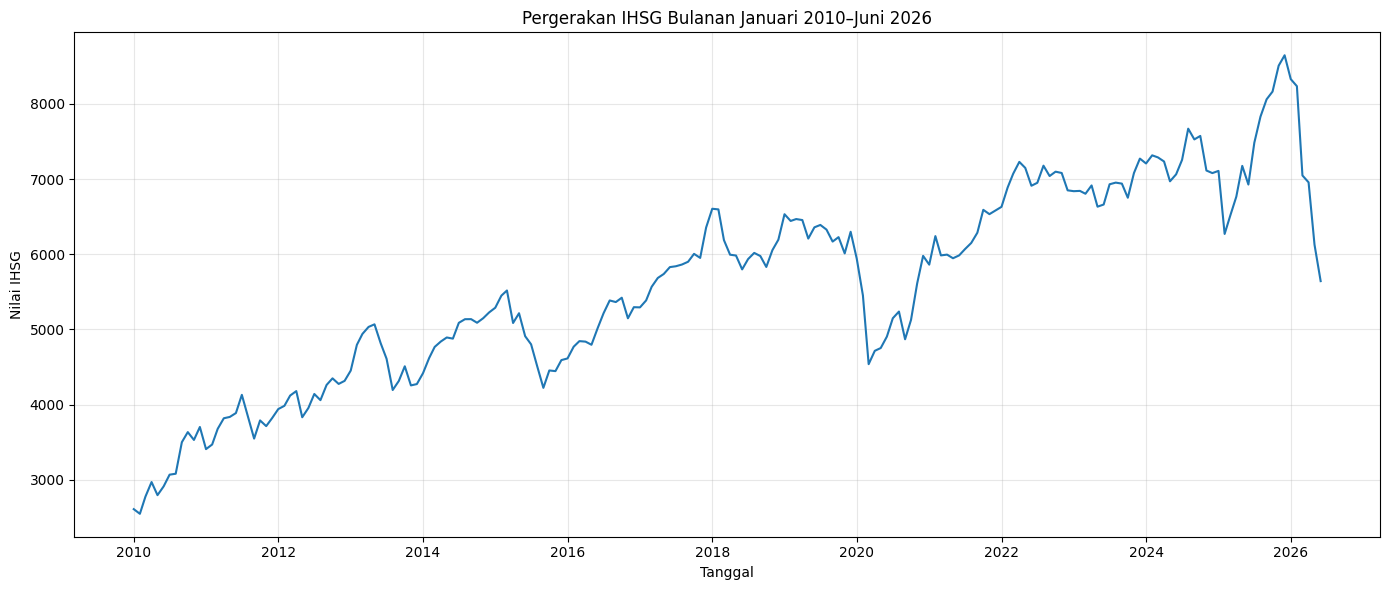

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df["IHSG"],
    linewidth=1.5
)

plt.title("Pergerakan IHSG Bulanan Januari 2010–Juni 2026")
plt.xlabel("Tanggal")
plt.ylabel("Nilai IHSG")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Rolling Mean dan Rolling Standar Deviasi

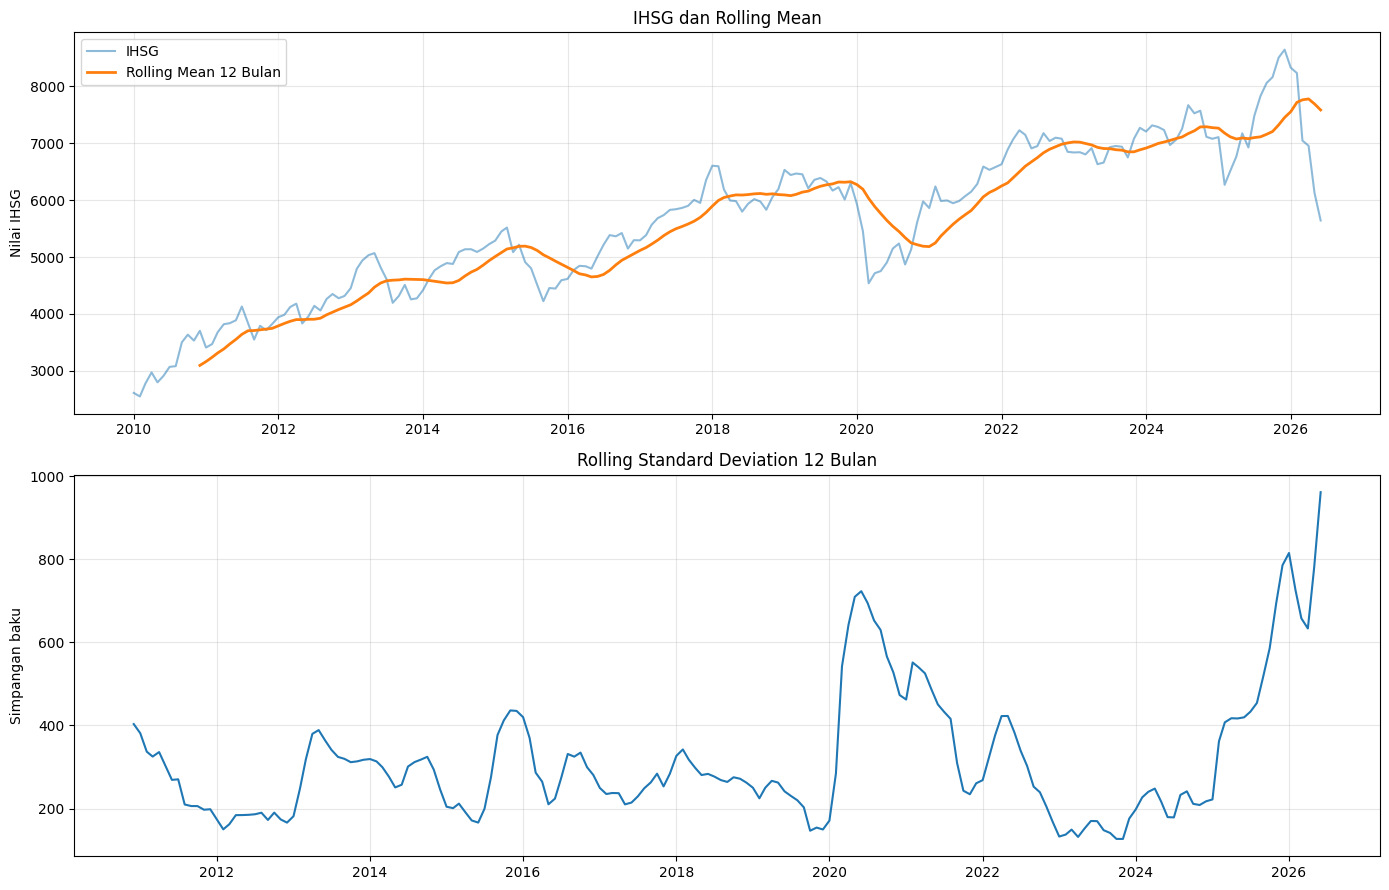

In [6]:
# ============================================================
# 5. ROLLING MEAN DAN ROLLING STANDARD DEVIATION
# ============================================================

df["Rolling_Mean_12"] = (
    df["IHSG"].rolling(window=12).mean()
)

df["Rolling_Std_12"] = (
    df["IHSG"].rolling(window=12).std()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Plot rolling mean
axes[0].plot(
    df.index,
    df["IHSG"],
    label="IHSG",
    alpha=0.5
)

axes[0].plot(
    df.index,
    df["Rolling_Mean_12"],
    label="Rolling Mean 12 Bulan",
    linewidth=2
)

axes[0].set_title("IHSG dan Rolling Mean")
axes[0].set_ylabel("Nilai IHSG")
axes[0].legend()

# Plot rolling standard deviation
axes[1].plot(
    df.index,
    df["Rolling_Std_12"],
    linewidth=1.5
)

axes[1].set_title("Rolling Standard Deviation 12 Bulan")
axes[1].set_ylabel("Simpangan baku")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

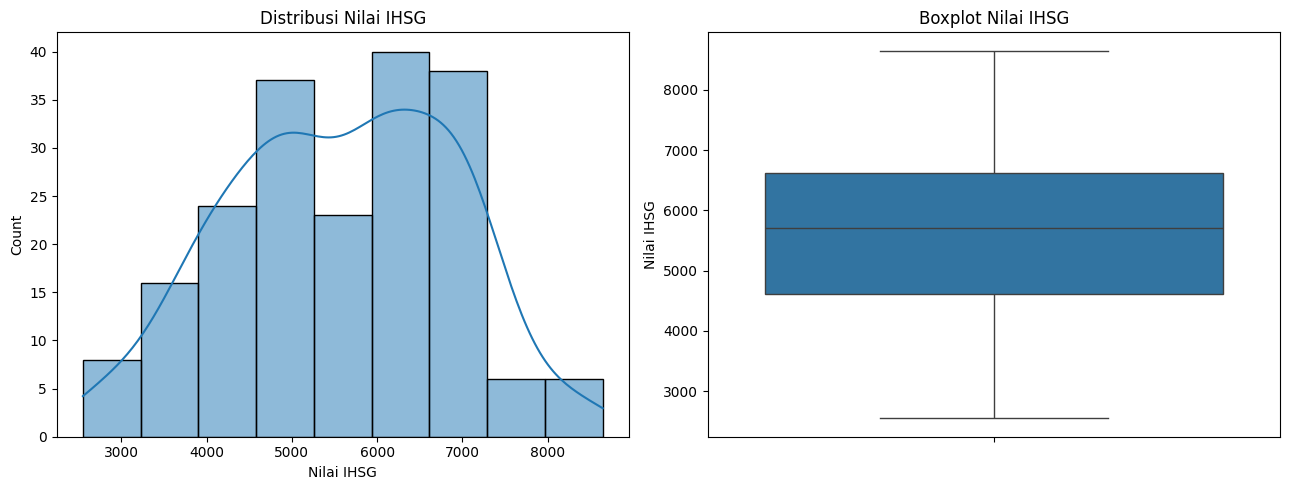

Batas bawah IQR: 1591.7825000000003
Batas atas IQR: 9644.5625
Jumlah pencilan potensial: 0


,IHSG,Rolling_Mean_12,Rolling_Std_12
Tanggal,,,


In [7]:
# ============================================================
# 6. HISTOGRAM DAN BOXPLOT
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    df["IHSG"].dropna(),
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribusi Nilai IHSG")
axes[0].set_xlabel("Nilai IHSG")

sns.boxplot(
    y=df["IHSG"].dropna(),
    ax=axes[1]
)

axes[1].set_title("Boxplot Nilai IHSG")
axes[1].set_ylabel("Nilai IHSG")

plt.tight_layout()
plt.show()

# Identifikasi pencilan berdasarkan aturan IQR
Q1 = df["IHSG"].quantile(0.25)
Q3 = df["IHSG"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

pencilan = df[
    (df["IHSG"] < batas_bawah) |
    (df["IHSG"] > batas_atas)
]

print("Batas bawah IQR:", batas_bawah)
print("Batas atas IQR:", batas_atas)
print("Jumlah pencilan potensial:", len(pencilan))

display(pencilan)

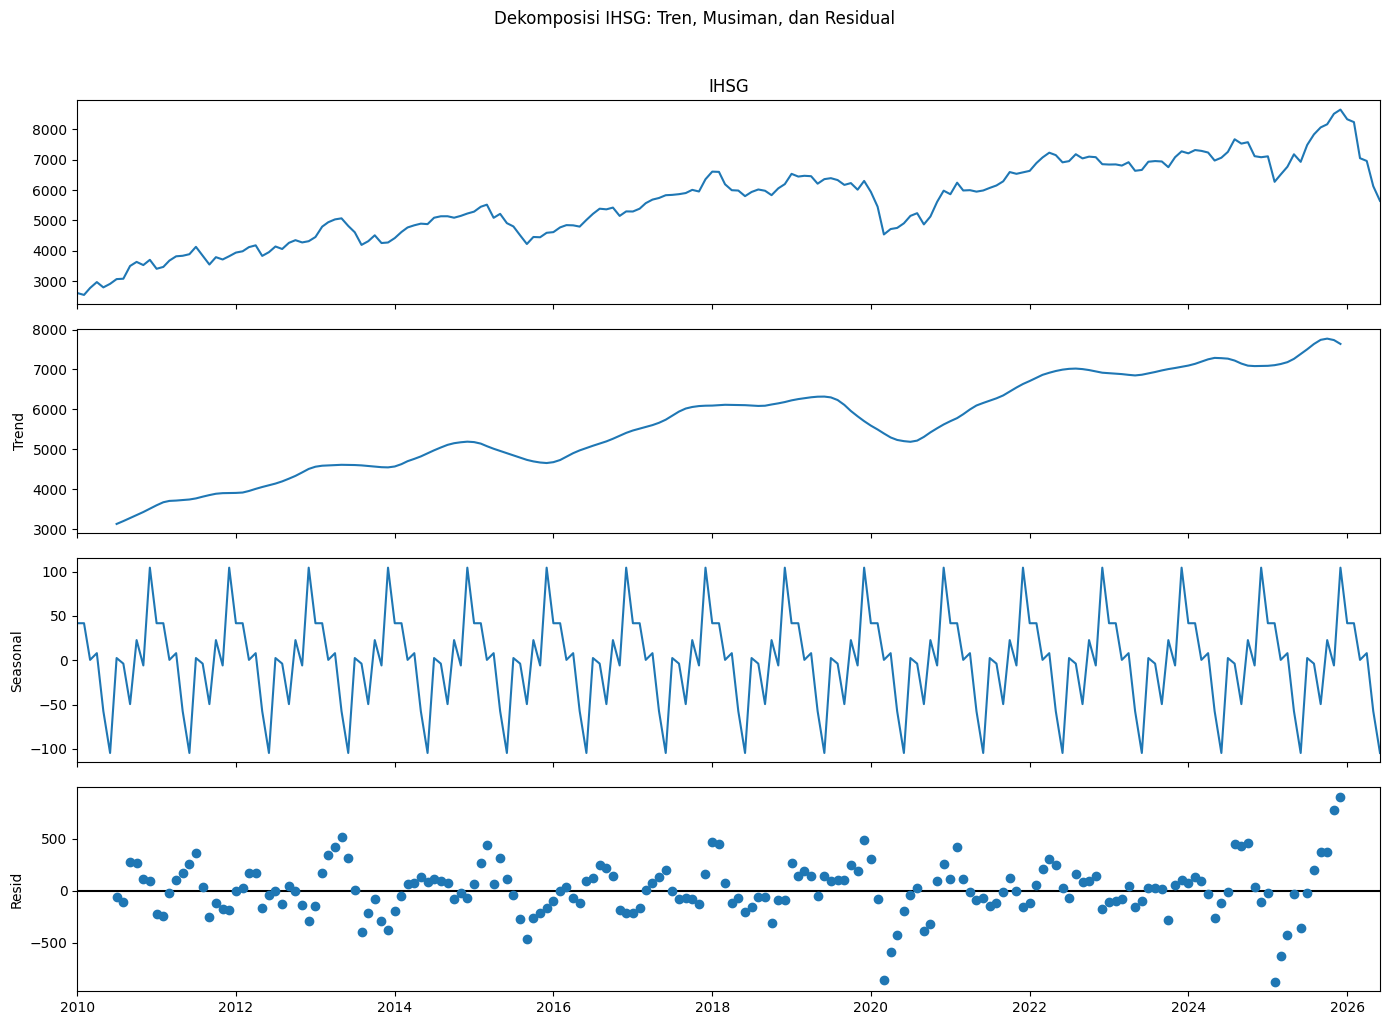

In [8]:
# ============================================================
# 7. DEKOMPOSISI TIME SERIES
# ============================================================

dekomposisi = seasonal_decompose(
    df["IHSG"].dropna(),
    model="additive",
    period=12
)

fig = dekomposisi.plot()
fig.set_size_inches(14, 10)
fig.suptitle(
    "Dekomposisi IHSG: Tren, Musiman, dan Residual",
    y=1.02
)

plt.tight_layout()
plt.show()

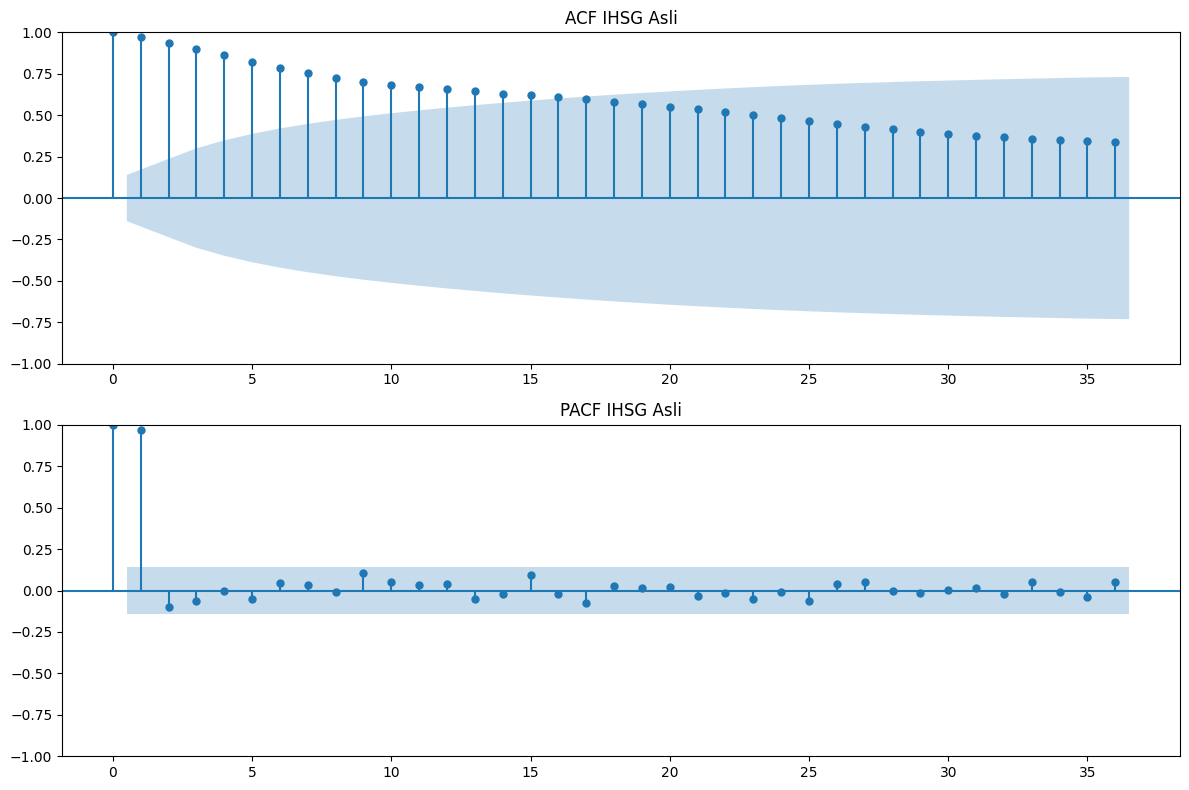

In [9]:
# ============================================================
# 8. ACF DAN PACF DATA IHSG ASLI
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    df["IHSG"].dropna(),
    lags=36,
    ax=axes[0]
)

axes[0].set_title("ACF IHSG Asli")

plot_pacf(
    df["IHSG"].dropna(),
    lags=36,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF IHSG Asli")

plt.tight_layout()
plt.show()

Jumlah observasi: 192

DATA TRAINING
Jumlah: 153
Periode: 2010-01-01 00:00:00 sampai 2022-09-01 00:00:00

DATA TESTING
Jumlah: 39
Periode: 2022-10-01 00:00:00 sampai 2025-12-01 00:00:00


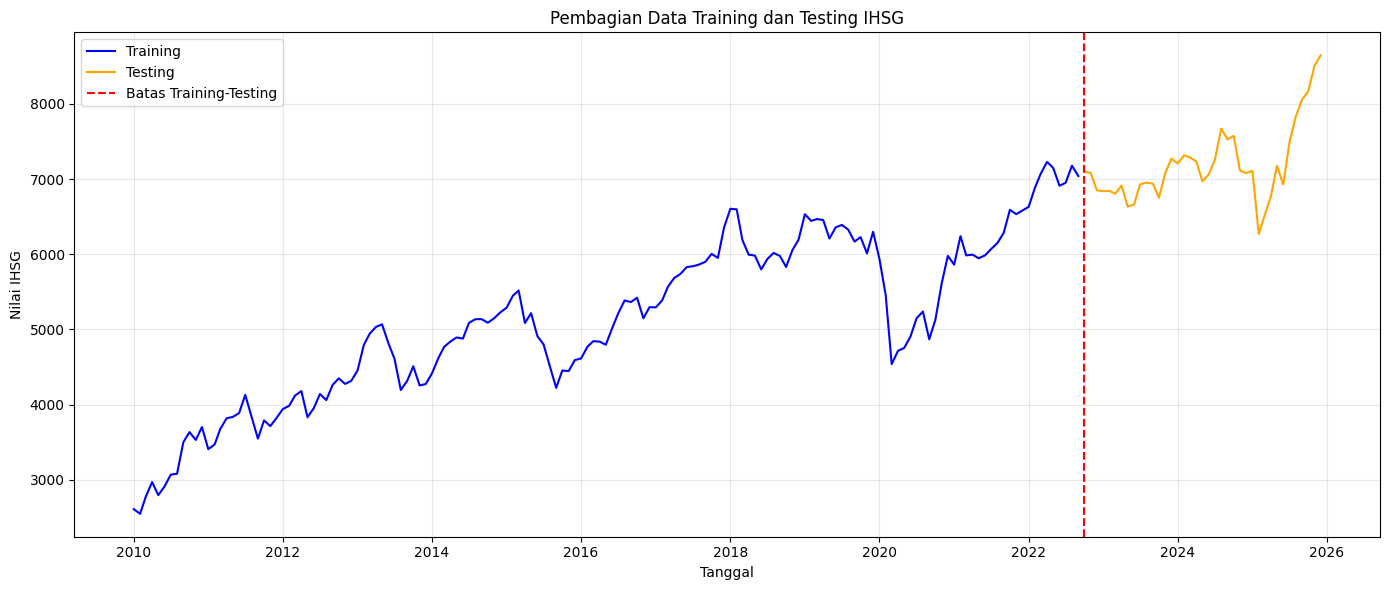

In [10]:
# ============================================================
# PEMBAGIAN DATA TRAINING DAN TESTING
# ============================================================

# Mengurutkan data berdasarkan waktu
df = df.sort_index()

# Membatasi periode penelitian
data = df.loc["2010-01-01":"2025-12-31", "IHSG"].dropna()

# Membagi data secara kronologis: 80% training, 20% testing
split_point = int(len(data) * 0.80)

train = data.iloc[:split_point]
test = data.iloc[split_point:]

# Menampilkan informasi pembagian
print("Jumlah observasi:", len(data))

print("\nDATA TRAINING")
print("Jumlah:", len(train))
print("Periode:", train.index.min(), "sampai", train.index.max())

print("\nDATA TESTING")
print("Jumlah:", len(test))
print("Periode:", test.index.min(), "sampai", test.index.max())

# Visualisasi training dan testing
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train,
    label="Training",
    color="blue"
)

plt.plot(
    test.index,
    test,
    label="Testing",
    color="orange"
)

plt.axvline(
    test.index[0],
    color="red",
    linestyle="--",
    label="Batas Training-Testing"
)

plt.title("Pembagian Data Training dan Testing IHSG")
plt.xlabel("Tanggal")
plt.ylabel("Nilai IHSG")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Skenario,Jumlah Training,Jumlah Testing,Awal Training,Akhir Training,Awal Testing,Akhir Testing
0,Skenario 1 (Testing mulai 2019),108,84,2010-01,2018-12,2019-01,2025-12
1,Skenario 2 (Testing mulai 2023),156,36,2010-01,2022-12,2023-01,2025-12


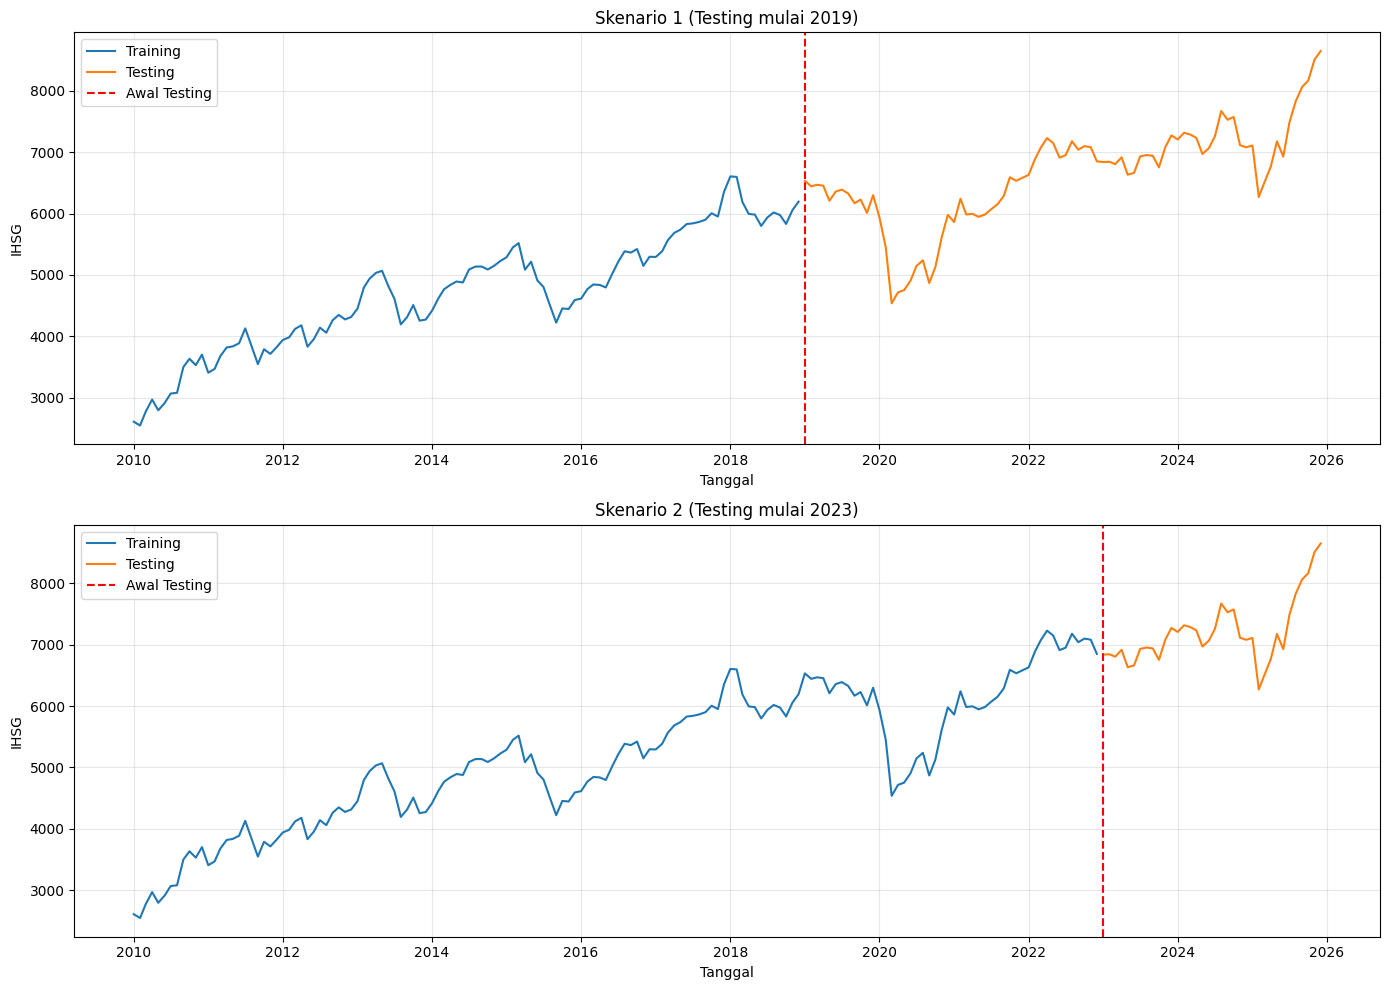

In [13]:

# ============================================================
# PEMBAGIAN DATA TRAINING-TESTING: 2 SKENARIO
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Mengurutkan data berdasarkan waktu
df = df.sort_index()

# Mengambil variabel IHSG pada periode penelitian
data = df.loc["2010-01-01":"2025-12-31", "IHSG"].dropna()

# Definisi skenario: tanggal awal testing
skenario = {
    "Skenario 1 (Testing mulai 2019)": "2019-01-01",
    "Skenario 2 (Testing mulai 2023)": "2023-01-01"
}

hasil_split = {}
ringkasan = []

for nama, tanggal_awal_test in skenario.items():

    tanggal_awal_test = pd.Timestamp(tanggal_awal_test)

    # Training: seluruh data sebelum tanggal awal testing
    train = data.loc[data.index < tanggal_awal_test]

    # Testing: data mulai tanggal awal testing
    test = data.loc[data.index >= tanggal_awal_test]

    # Menyimpan data masing-masing skenario
    hasil_split[nama] = {
        "train": train,
        "test": test
    }

    # Ringkasan pembagian
    ringkasan.append({
        "Skenario": nama,
        "Jumlah Training": len(train),
        "Jumlah Testing": len(test),
        "Awal Training": train.index.min().strftime("%Y-%m"),
        "Akhir Training": train.index.max().strftime("%Y-%m"),
        "Awal Testing": test.index.min().strftime("%Y-%m"),
        "Akhir Testing": test.index.max().strftime("%Y-%m")
    })

# Menampilkan tabel ringkasan
tabel_split = pd.DataFrame(ringkasan)
display(tabel_split)

# ============================================================
# VISUALISASI PEMBAGIAN TRAINING-TESTING
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax, (nama, bagian) in zip(axes, hasil_split.items()):

    train = bagian["train"]
    test = bagian["test"]

    ax.plot(
        train.index,
        train,
        label="Training"
    )

    ax.plot(
        test.index,
        test,
        label="Testing"
    )

    ax.axvline(
        test.index[0],
        linestyle="--",
        color="red",
        label="Awal Testing"
    )

    ax.set_title(nama)
    ax.set_xlabel("Tanggal")
    ax.set_ylabel("IHSG")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [14]:

# ============================================================
# 1. STATISTIK DESKRIPTIF DATA TRAINING
# ============================================================

for nama, bagian in hasil_split.items():

    train = bagian["train"]

    print("\n" + "=" * 60)
    print(nama)
    print("Periode:", train.index.min(), "sampai", train.index.max())
    print("Jumlah observasi:", len(train))
    print("=" * 60)

    display(train.describe().to_frame(name="IHSG"))

    print("Skewness:", train.skew())
    print("Kurtosis:", train.kurtosis())



Skenario 1 (Testing mulai 2019)
Periode: 2010-01-01 00:00:00 sampai 2018-12-01 00:00:00
Jumlah observasi: 108


,IHSG
count,108.000000
mean,4702.503704
std,942.653485
min,2549.030000
25%,4041.550000
50%,4796.330000
75%,5370.120000
max,6605.630000


Skewness: -0.18080446592839586
Kurtosis: -0.549082268912465

Skenario 2 (Testing mulai 2023)
Periode: 2010-01-01 00:00:00 sampai 2022-12-01 00:00:00
Jumlah observasi: 156


,IHSG
count,156.000000
mean,5156.186667
std,1110.936504
min,2549.030000
25%,4316.562500
50%,5143.245000
75%,5998.160000
max,7228.910000


Skewness: -0.1974360288792428
Kurtosis: -0.6615445089422121


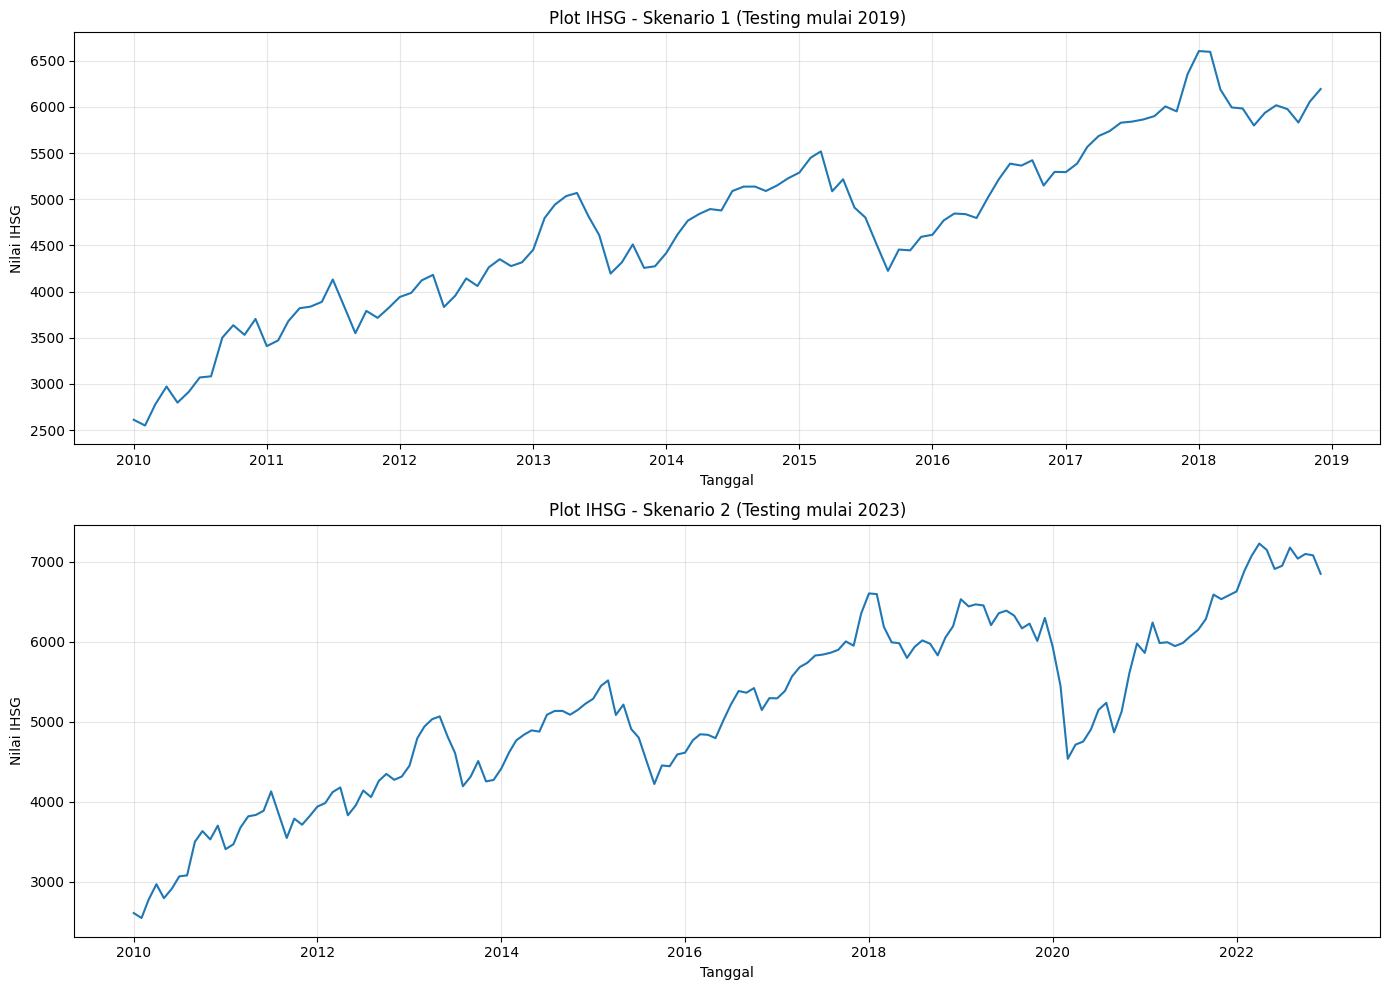

In [15]:

# ============================================================
# 2. PLOT DATA TRAINING
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

for ax, (nama, bagian) in zip(axes, hasil_split.items()):

    train = bagian["train"]

    ax.plot(
        train.index,
        train.values,
        linewidth=1.5
    )

    ax.set_title(f"Plot IHSG - {nama}")
    ax.set_xlabel("Tanggal")
    ax.set_ylabel("Nilai IHSG")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


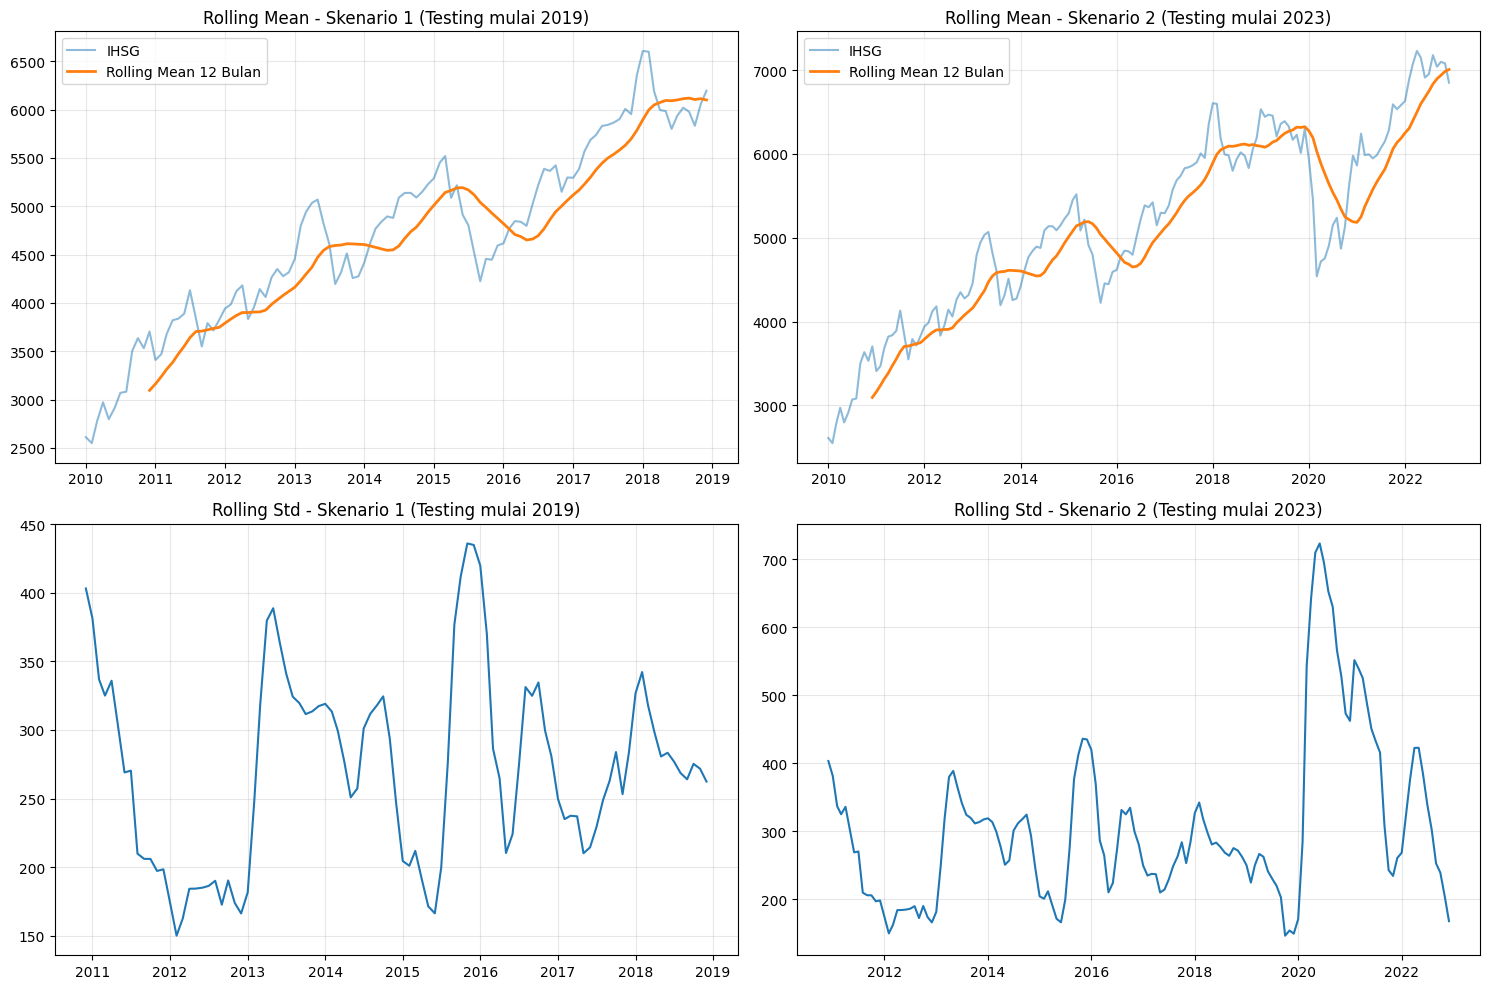

In [16]:

# ============================================================
# 3. ROLLING MEAN DAN ROLLING STANDARD DEVIATION
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, (nama, bagian) in enumerate(hasil_split.items()):

    train = bagian["train"]

    rolling_mean = train.rolling(12).mean()
    rolling_std = train.rolling(12).std()

    axes[0, col].plot(
        train.index, train,
        label="IHSG", alpha=0.5
    )
    axes[0, col].plot(
        train.index, rolling_mean,
        label="Rolling Mean 12 Bulan", linewidth=2
    )
    axes[0, col].set_title(f"Rolling Mean - {nama}")
    axes[0, col].legend()
    axes[0, col].grid(alpha=0.3)

    axes[1, col].plot(
        train.index, rolling_std
    )
    axes[1, col].set_title(f"Rolling Std - {nama}")
    axes[1, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()


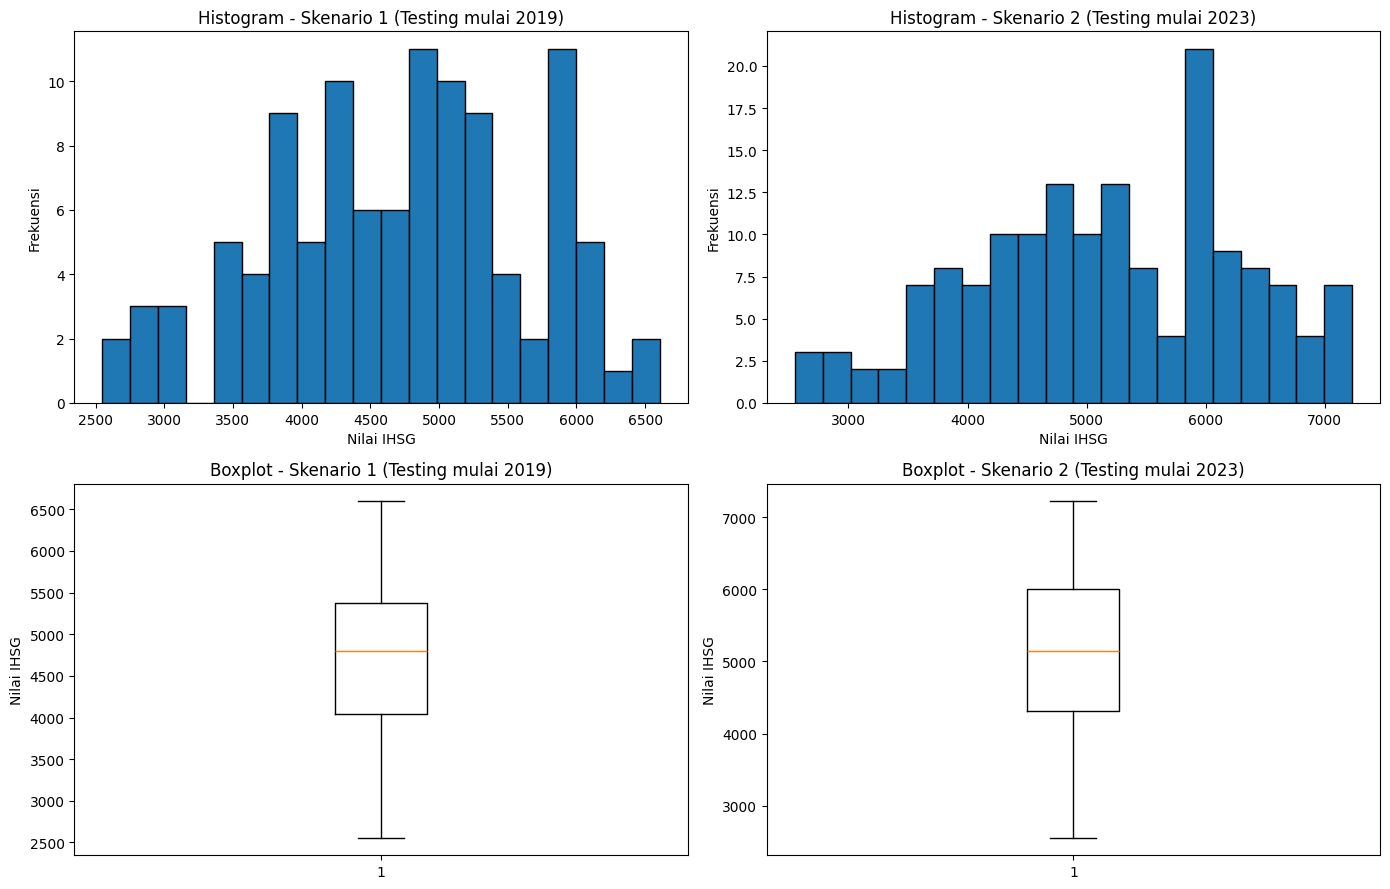

In [17]:

# ============================================================
# 4. DISTRIBUSI DAN PENCILAN POTENSIAL
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, (nama, bagian) in enumerate(hasil_split.items()):

    train = bagian["train"]

    axes[0, col].hist(
        train.dropna(),
        bins=20,
        edgecolor="black"
    )
    axes[0, col].set_title(f"Histogram - {nama}")
    axes[0, col].set_xlabel("Nilai IHSG")
    axes[0, col].set_ylabel("Frekuensi")

    axes[1, col].boxplot(
        train.dropna(),
        vert=True
    )
    axes[1, col].set_title(f"Boxplot - {nama}")
    axes[1, col].set_ylabel("Nilai IHSG")

plt.tight_layout()
plt.show()



 Skenario 1 (Testing mulai 2019)


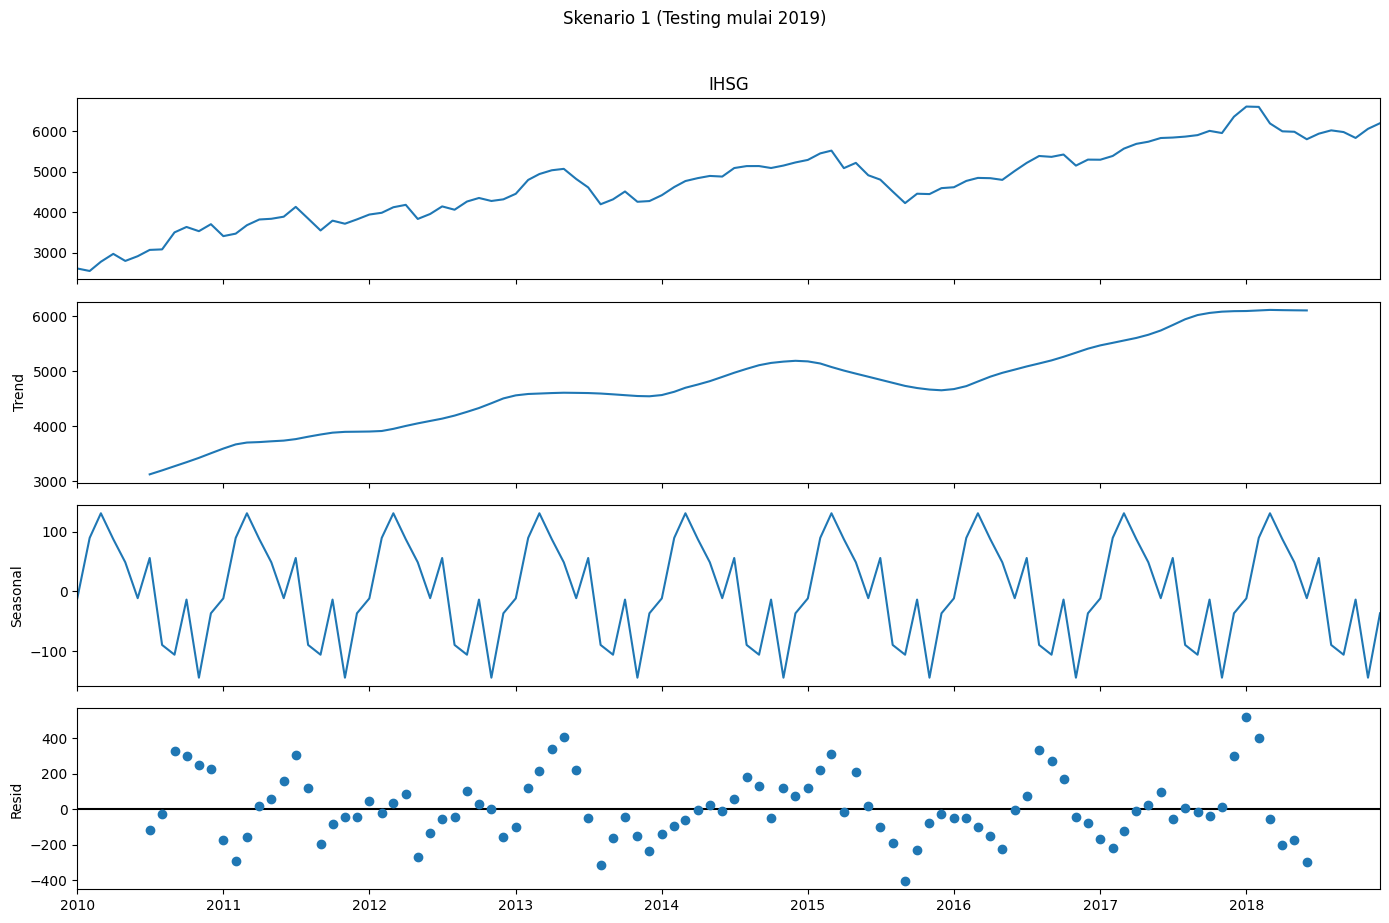


 Skenario 2 (Testing mulai 2023)


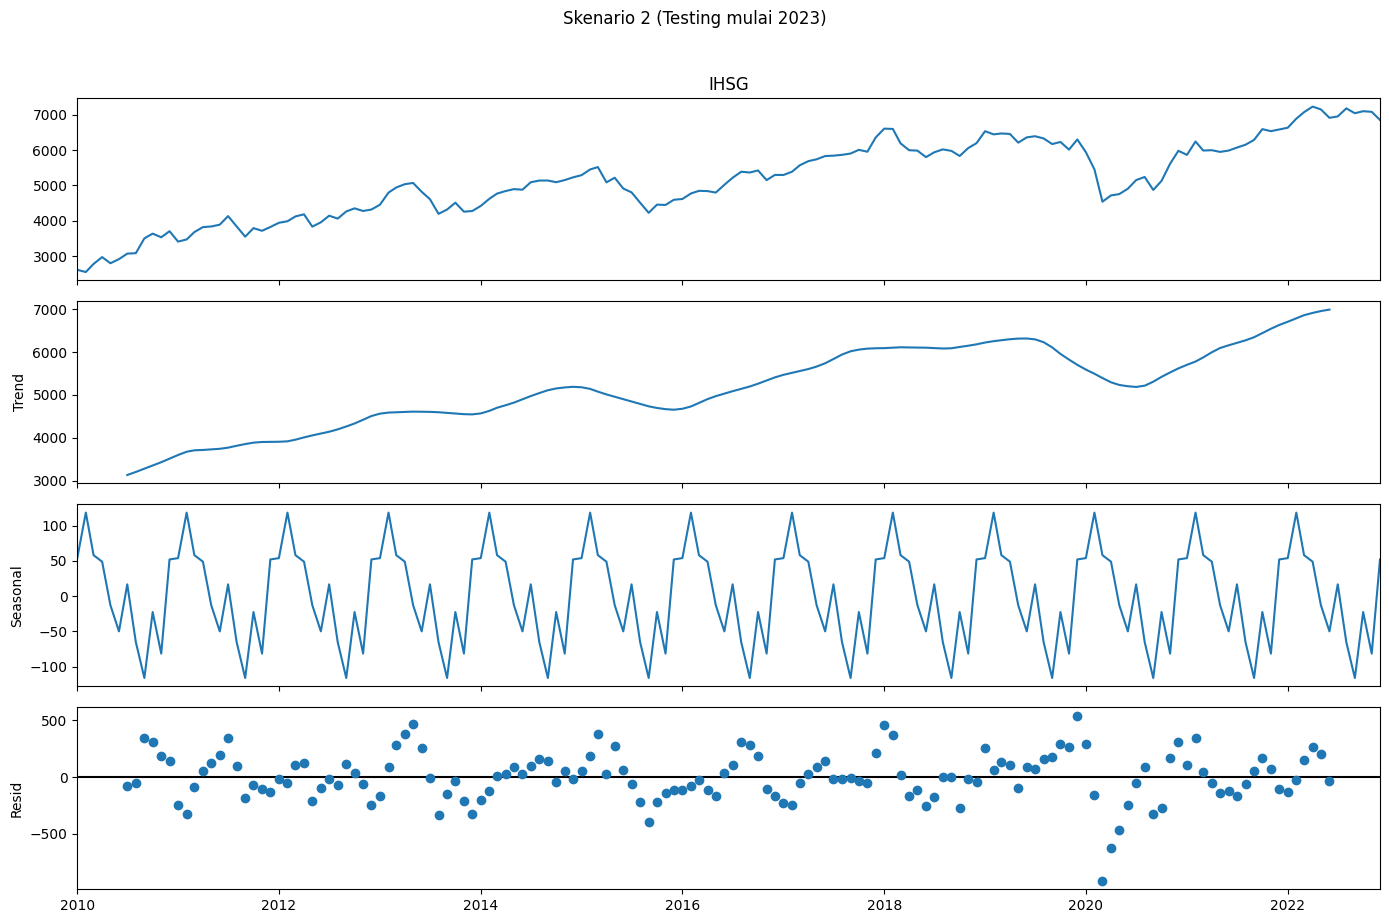

In [18]:

# ============================================================
# 5. DEKOMPOSISI DATA TRAINING
# ============================================================

from statsmodels.tsa.seasonal import seasonal_decompose

for nama, bagian in hasil_split.items():

    train = bagian["train"].asfreq("MS")

    print("\n", nama)

    if train.isna().any():
        print(
            "Ada bulan yang hilang. "
            "Periksa kelengkapan data sebelum dekomposisi."
        )
        continue

    dekomposisi = seasonal_decompose(
        train,
        model="additive",
        period=12
    )

    fig = dekomposisi.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle(nama, y=1.02)
    plt.tight_layout()
    plt.show()


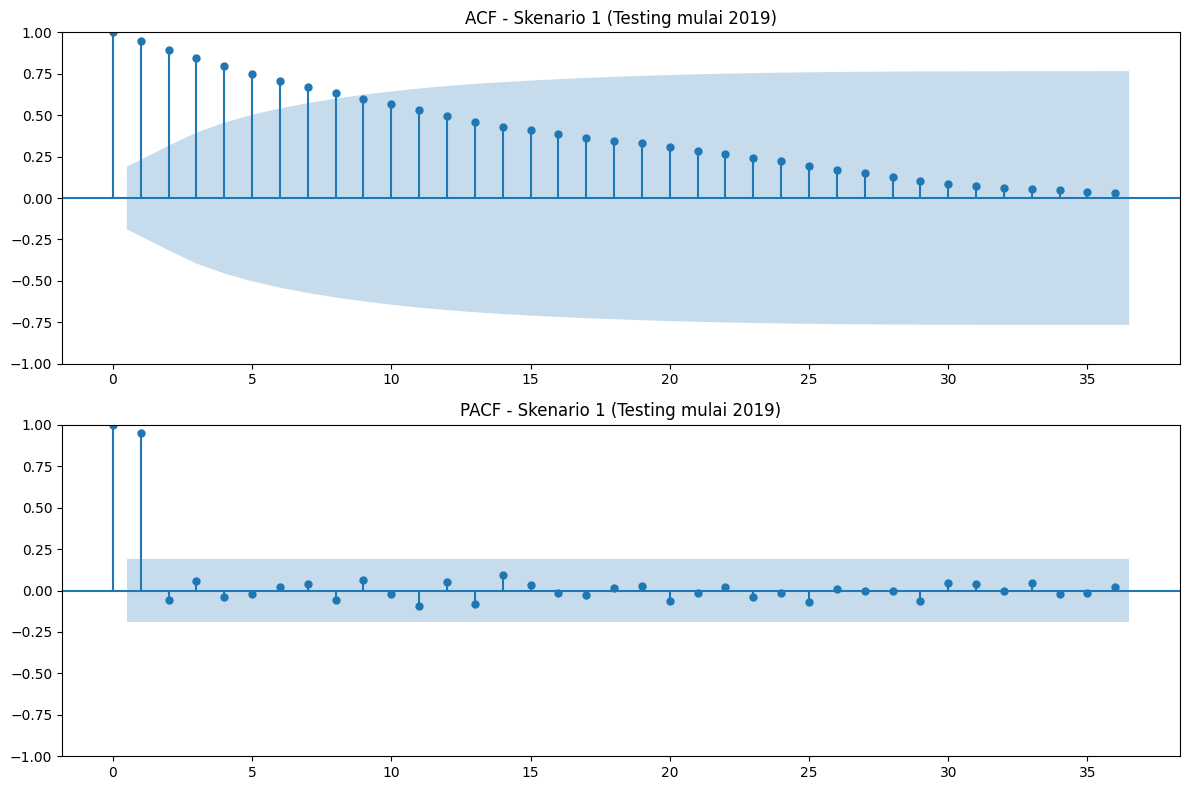

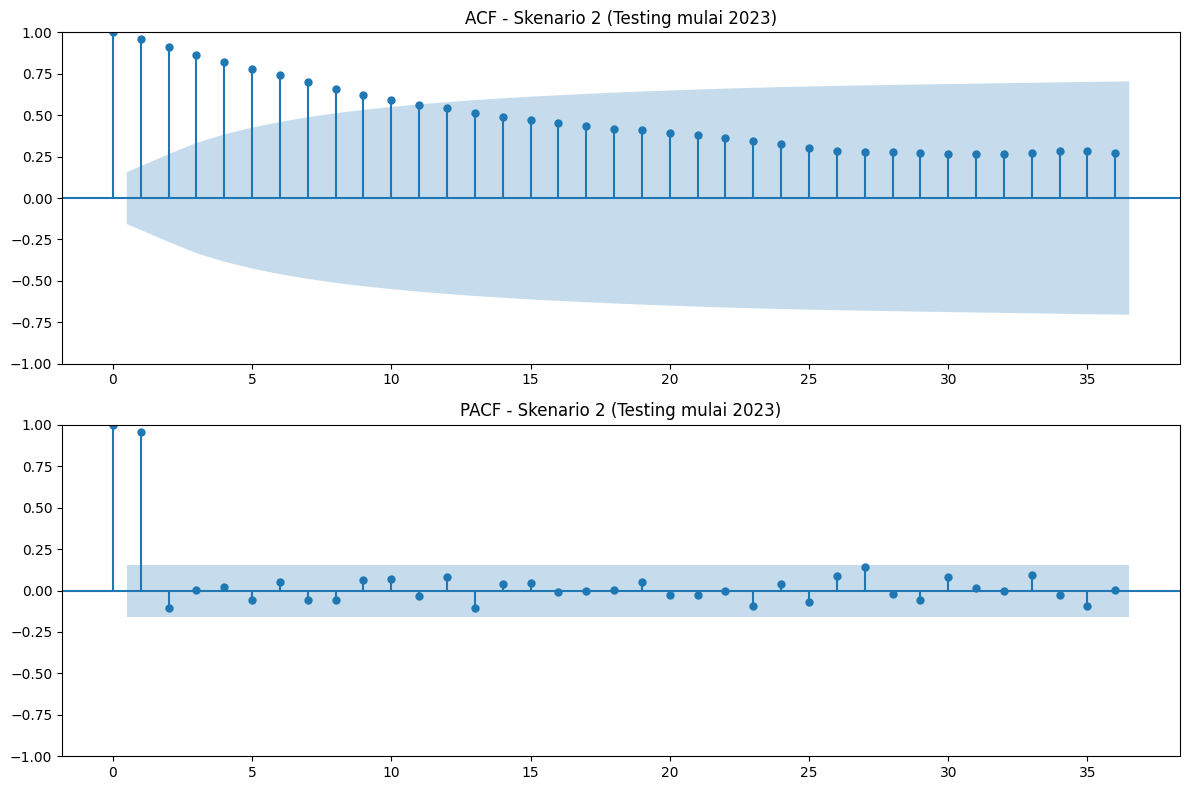

In [19]:

# ============================================================
# 6. ACF DAN PACF DATA TRAINING
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

for nama, bagian in hasil_split.items():

    train = bagian["train"].dropna()

    # Maksimal 36 lag dan tidak melebihi batas sampel
    jumlah_lag = min(36, max(1, len(train) // 2 - 1))

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    plot_acf(
        train,
        lags=jumlah_lag,
        ax=axes[0]
    )
    axes[0].set_title(f"ACF - {nama}")

    plot_pacf(
        train,
        lags=jumlah_lag,
        method="ywm",
        ax=axes[1]
    )
    axes[1].set_title(f"PACF - {nama}")

    plt.tight_layout()
    plt.show()


In [20]:

# ============================================================
# 7. UJI STASIONERITAS DATA TRAINING
# ============================================================

from statsmodels.tsa.stattools import adfuller, kpss

def uji_stasioneritas(data, nama):
    data = data.dropna()

    print("\n", "=" * 50)
    print(nama)
    print("=" * 50)

    # ADF
    adf_result = adfuller(data, autolag="AIC")

    print("\nADF")
    print("Statistik:", adf_result[0])
    print("P-value:", adf_result[1])

    if adf_result[1] < 0.05:
        print("Kesimpulan: Tolak H0 akar unit.")
    else:
        print("Kesimpulan: Belum cukup bukti menolak H0 akar unit.")

    # KPSS
    kpss_result = kpss(
        data,
        regression="c",
        nlags="auto"
    )

    print("\nKPSS")
    print("Statistik:", kpss_result[0])
    print("P-value:", kpss_result[1])

    if kpss_result[1] < 0.05:
        print("Kesimpulan: Tolak H0 stasioneritas.")
    else:
        print("Kesimpulan: Belum cukup bukti menolak H0 stasioneritas.")


for nama, bagian in hasil_split.items():
    uji_stasioneritas(
        bagian["train"],
        nama
    )



Skenario 1 (Testing mulai 2019)

ADF
Statistik: -1.616803408149773
P-value: 0.47440554141134944
Kesimpulan: Belum cukup bukti menolak H0 akar unit.

KPSS
Statistik: 1.472273315993282
P-value: 0.01
Kesimpulan: Tolak H0 stasioneritas.

Skenario 2 (Testing mulai 2023)

ADF
Statistik: -1.9883811168132182
P-value: 0.2916906965481314
Kesimpulan: Belum cukup bukti menolak H0 akar unit.

KPSS
Statistik: 1.5793988239176457
P-value: 0.01
Kesimpulan: Tolak H0 stasioneritas.


/tmp/ipykernel_1784/2491236343.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(data, autolag="AIC")
/tmp/ipykernel_1784/2491236343.py:27: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_1784/2491236343.py:27: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_objec

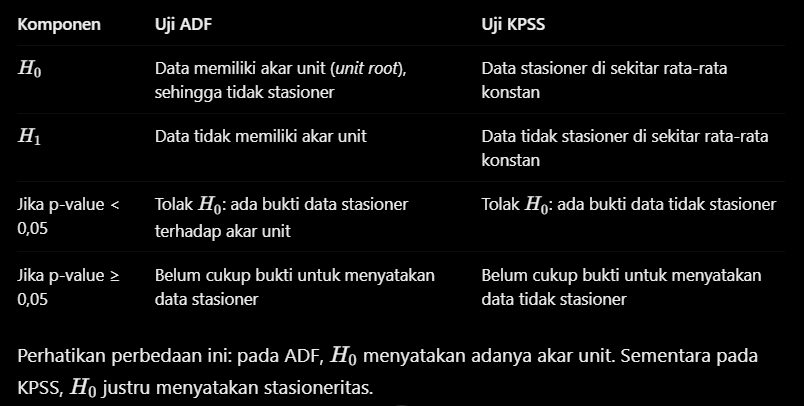

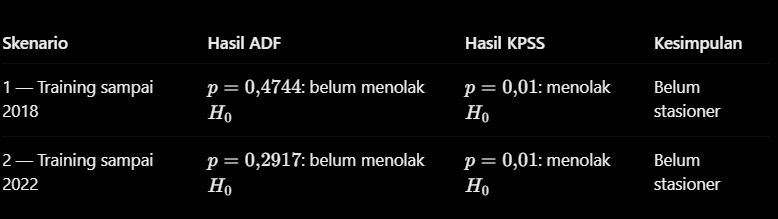


Skenario 1 (Testing mulai 2019)
Lambda optimal: 1.2738882915163319
Interpretasi awal: Transformasi berpangkat positif


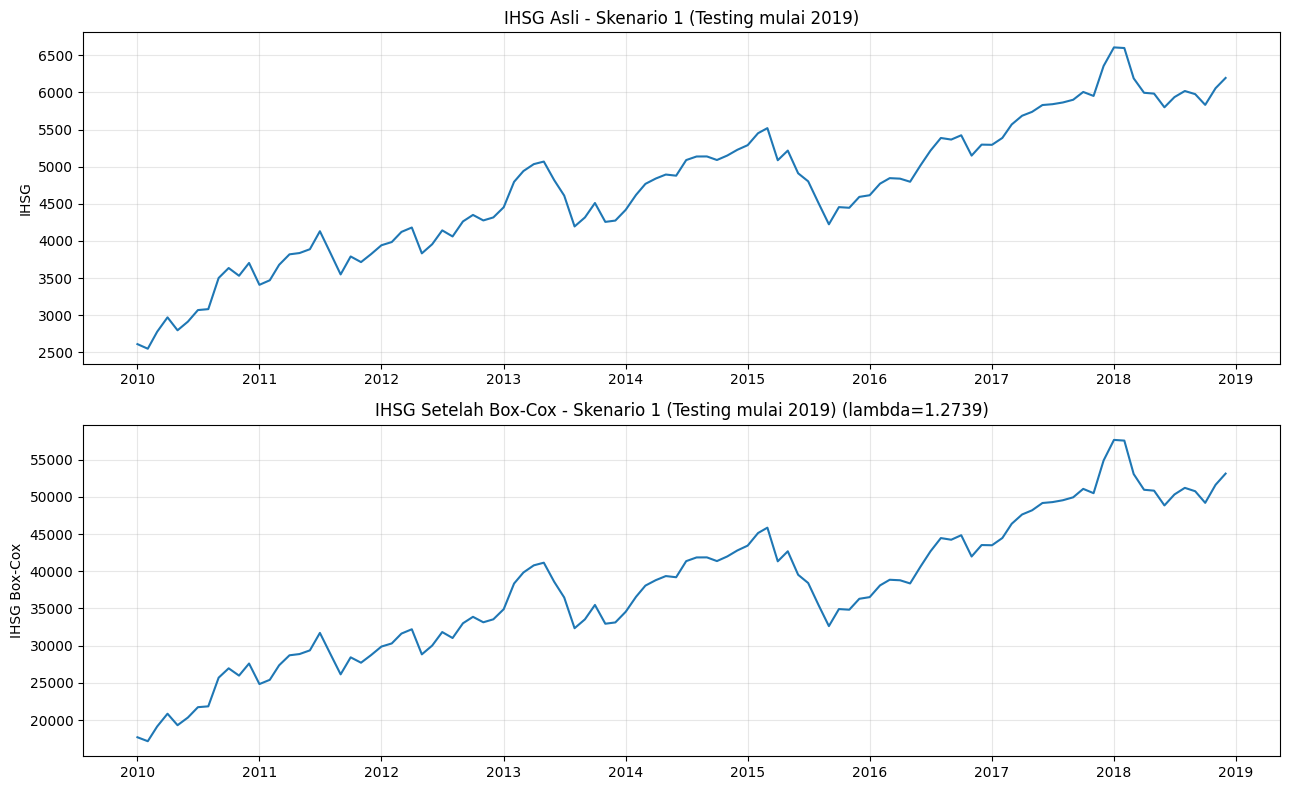


Skenario 2 (Testing mulai 2023)
Lambda optimal: 1.2763078669237065
Interpretasi awal: Transformasi berpangkat positif


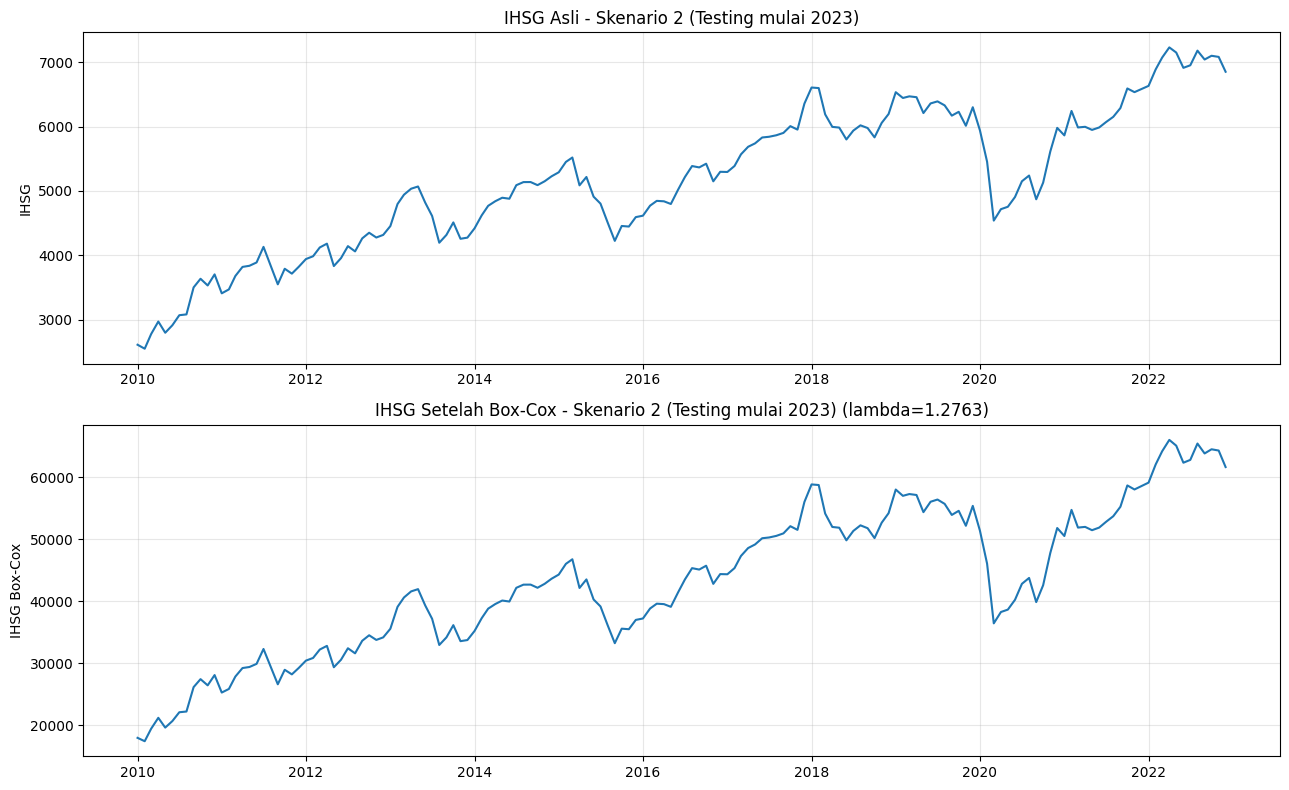

In [21]:

# ============================================================
# UJI BOX-COX UNTUK DUA SKENARIO TRAINING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox

hasil_boxcox = {}

for nama, bagian in hasil_split.items():

    train = bagian["train"].dropna()

    print("\n" + "=" * 60)
    print(nama)
    print("=" * 60)

    # Box-Cox standar mensyaratkan data positif
    if (train <= 0).any():
        print("Box-Cox tidak dapat diterapkan karena ada nilai <= 0.")
        continue

    # Estimasi lambda dan transformasi Box-Cox
    data_boxcox, lambda_optimal = boxcox(train)

    hasil_boxcox[nama] = {
        "lambda": lambda_optimal,
        "data_transformasi": pd.Series(
            data_boxcox,
            index=train.index,
            name="IHSG_BoxCox"
        )
    }

    print("Lambda optimal:", lambda_optimal)

    # Interpretasi lambda secara umum
    if np.isclose(lambda_optimal, 1, atol=0.1):
        interpretasi = "Transformasi mendekati data asli"
    elif np.isclose(lambda_optimal, 0, atol=0.1):
        interpretasi = "Transformasi mendekati logaritma"
    elif lambda_optimal < 0:
        interpretasi = "Transformasi berpangkat negatif"
    else:
        interpretasi = "Transformasi berpangkat positif"

    print("Interpretasi awal:", interpretasi)

    # Plot sebelum dan sesudah transformasi
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))

    axes[0].plot(train.index, train)
    axes[0].set_title(f"IHSG Asli - {nama}")
    axes[0].set_ylabel("IHSG")
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        hasil_boxcox[nama]["data_transformasi"].index,
        hasil_boxcox[nama]["data_transformasi"]
    )
    axes[1].set_title(
        f"IHSG Setelah Box-Cox - {nama} (lambda={lambda_optimal:.4f})"
    )
    axes[1].set_ylabel("IHSG Box-Cox")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


In [22]:

# ============================================================
# RINGKASAN LAMBDA BOX-COX
# ============================================================

ringkasan_boxcox = pd.DataFrame([
    {
        "Skenario": nama,
        "Lambda Optimal": hasil["lambda"]
    }
    for nama, hasil in hasil_boxcox.items()
])

display(ringkasan_boxcox)


,Skenario,Lambda Optimal
0,Skenario 1 (Testing mulai 2019),1.273888
1,Skenario 2 (Testing mulai 2023),1.276308



Skenario 1 (Testing mulai 2019)
Lambda optimal       : 1.273888
Selang kepercayaan 95%: (0.445618, 2.140503)
Lambda 1 termasuk CI : True
Lambda 0 termasuk CI : False


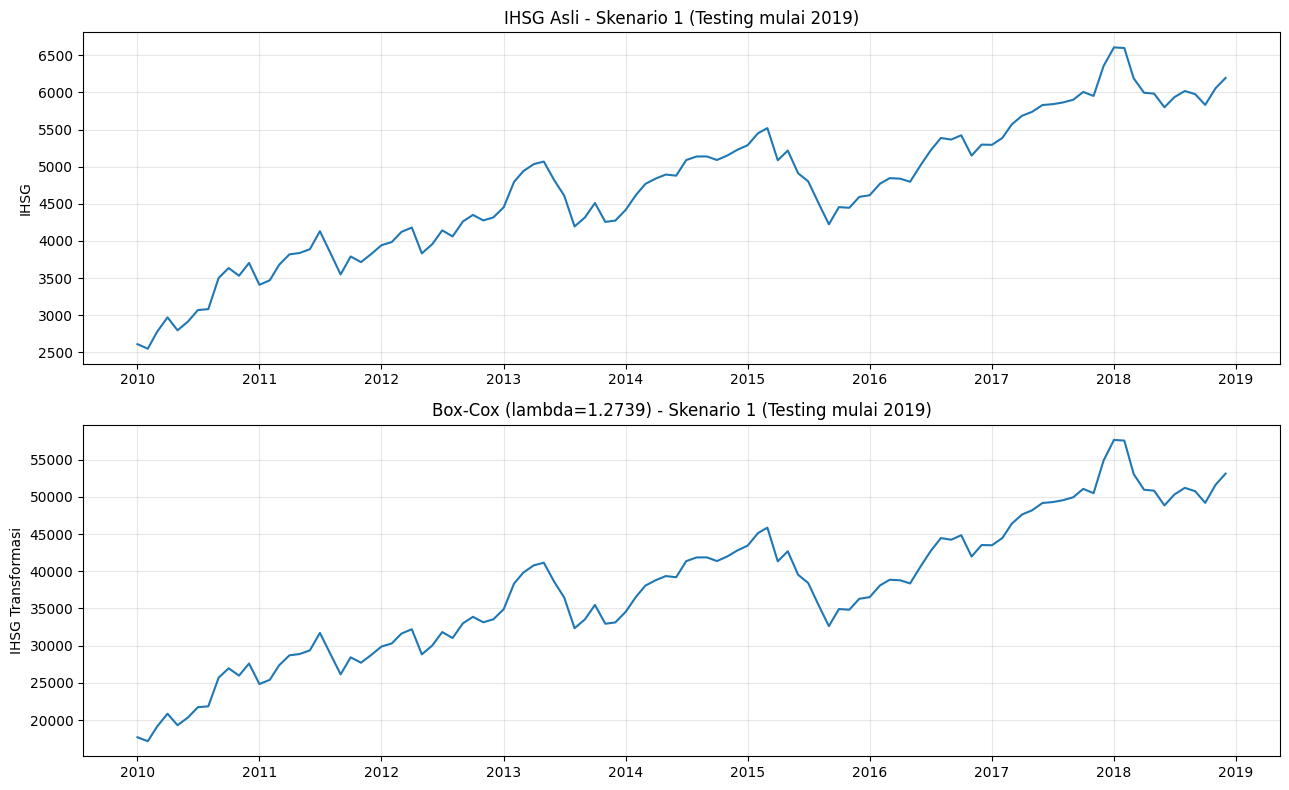


Skenario 2 (Testing mulai 2023)
Lambda optimal       : 1.276308
Selang kepercayaan 95%: (0.623402, 1.958297)
Lambda 1 termasuk CI : True
Lambda 0 termasuk CI : False


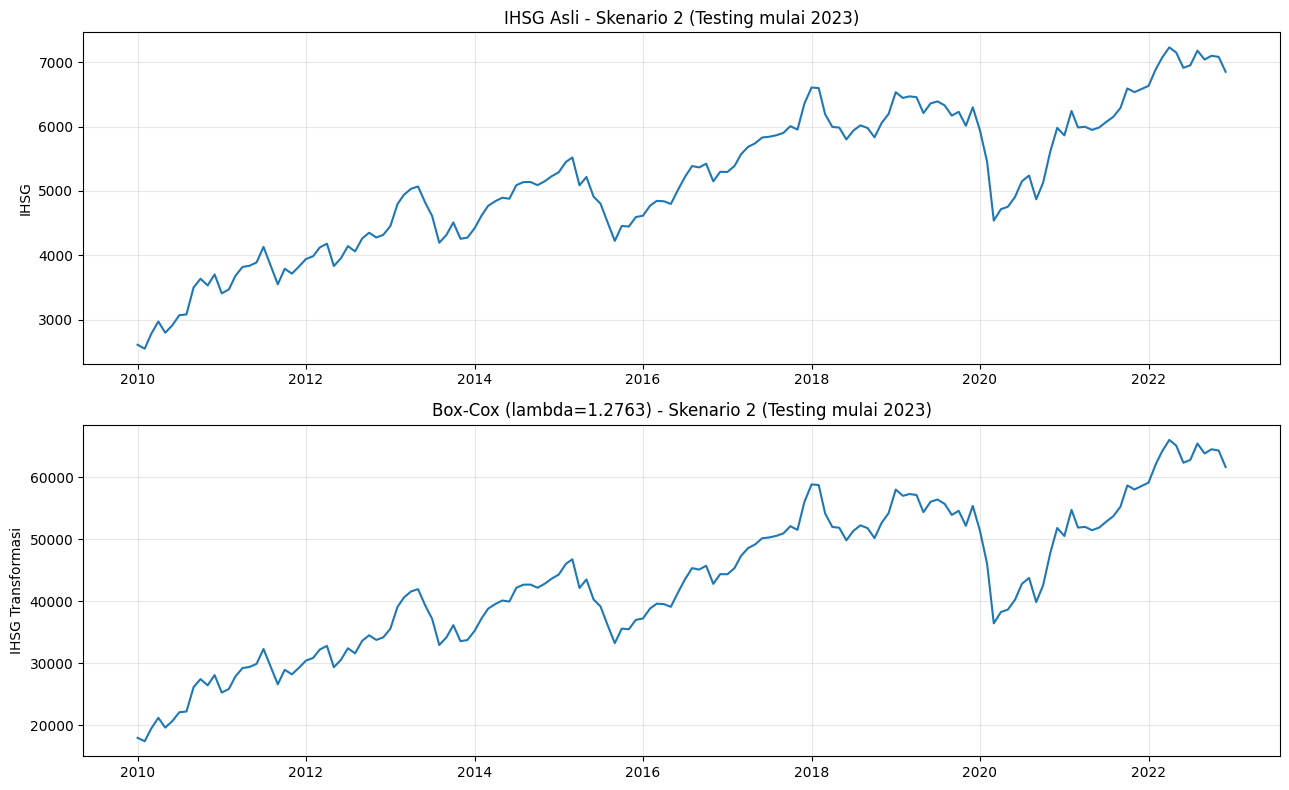

,Skenario,Lambda Optimal,CI 95% Bawah,CI 95% Atas,Lambda 1 dalam CI,Lambda 0 dalam CI
0,Skenario 1 (Testing mulai 2019),1.273888,0.445618,2.140503,True,False
1,Skenario 2 (Testing mulai 2023),1.276308,0.623402,1.958297,True,False


In [23]:

# ============================================================
# UJI BOX-COX DENGAN SELANG KEPERCAYAAN 95%
# UNTUK DUA SKENARIO TRAINING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox

hasil_boxcox = {}

for nama, bagian in hasil_split.items():

    train = bagian["train"].dropna()

    print("\n" + "=" * 65)
    print(nama)
    print("=" * 65)

    # Box-Cox memerlukan data bernilai positif
    if (train <= 0).any():
        print("Tidak dapat dilakukan: terdapat nilai IHSG <= 0.")
        continue

    # Transformasi Box-Cox dan selang kepercayaan 95%
    data_transformasi, lambda_optimal, ci = boxcox(
        train.to_numpy(),
        alpha=0.05
    )

    lambda_bawah, lambda_atas = ci

    hasil_boxcox[nama] = {
        "lambda": lambda_optimal,
        "CI_bawah": lambda_bawah,
        "CI_atas": lambda_atas,
        "data_transformasi": pd.Series(
            data_transformasi,
            index=train.index
        )
    }

    print(f"Lambda optimal       : {lambda_optimal:.6f}")
    print(
        f"Selang kepercayaan 95%: "
        f"({lambda_bawah:.6f}, {lambda_atas:.6f})"
    )

    # Interpretasi apakah lambda 1 dan 0 masuk dalam CI
    print(
        "Lambda 1 termasuk CI :",
        lambda_bawah <= 1 <= lambda_atas
    )
    print(
        "Lambda 0 termasuk CI :",
        lambda_bawah <= 0 <= lambda_atas
    )

    # Plot data asli dan hasil transformasi
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))

    axes[0].plot(train.index, train)
    axes[0].set_title(f"IHSG Asli - {nama}")
    axes[0].set_ylabel("IHSG")
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        train.index,
        data_transformasi
    )
    axes[1].set_title(
        f"Box-Cox (lambda={lambda_optimal:.4f}) - {nama}"
    )
    axes[1].set_ylabel("IHSG Transformasi")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

# ============================================================
# TABEL RINGKASAN
# ============================================================

ringkasan_boxcox = pd.DataFrame([
    {
        "Skenario": nama,
        "Lambda Optimal": hasil["lambda"],
        "CI 95% Bawah": hasil["CI_bawah"],
        "CI 95% Atas": hasil["CI_atas"],
        "Lambda 1 dalam CI":
            hasil["CI_bawah"] <= 1 <= hasil["CI_atas"],
        "Lambda 0 dalam CI":
            hasil["CI_bawah"] <= 0 <= hasil["CI_atas"]
    }
    for nama, hasil in hasil_boxcox.items()
])

display(ringkasan_boxcox)


- Differencing 1

In [24]:

# ============================================================
# FIRST DIFFERENCING DAN UJI STASIONERITAS
# ============================================================

from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

hasil_diff = {}

for nama, bagian in hasil_split.items():

    train = bagian["train"].dropna()

    # Differencing pertama
    train_diff1 = train.diff().dropna()

    hasil_diff[nama] = train_diff1

    print("\n" + "=" * 60)
    print(nama, "- FIRST DIFFERENCING")
    print("=" * 60)

    # Uji ADF
    adf_result = adfuller(
        train_diff1,
        autolag="AIC"
    )

    print("\nADF")
    print("Statistik ADF:", adf_result[0])
    print("P-value ADF:", adf_result[1])

    if adf_result[1] < 0.05:
        print("Kesimpulan ADF: Tolak H0 akar unit.")
    else:
        print("Kesimpulan ADF: Belum cukup bukti menolak H0.")

    # Uji KPSS
    kpss_result = kpss(
        train_diff1,
        regression="c",
        nlags="auto"
    )

    print("\nKPSS")
    print("Statistik KPSS:", kpss_result[0])
    print("P-value KPSS:", kpss_result[1])

    if kpss_result[1] < 0.05:
        print("Kesimpulan KPSS: Tolak H0 stasioneritas.")
    else:
        print("Kesimpulan KPSS: Belum cukup bukti menolak H0 stasioneritas.")



Skenario 1 (Testing mulai 2019) - FIRST DIFFERENCING

ADF
Statistik ADF: -9.462274980039004
P-value ADF: 4.3218149087986354e-16
Kesimpulan ADF: Tolak H0 akar unit.

KPSS
Statistik KPSS: 0.07349313878481799
P-value KPSS: 0.1
Kesimpulan KPSS: Belum cukup bukti menolak H0 stasioneritas.

Skenario 2 (Testing mulai 2023) - FIRST DIFFERENCING

ADF
Statistik ADF: -11.014262130637787
P-value ADF: 6.21364688579467e-20
Kesimpulan ADF: Tolak H0 akar unit.

KPSS
Statistik KPSS: 0.07696699661761525
P-value KPSS: 0.1
Kesimpulan KPSS: Belum cukup bukti menolak H0 stasioneritas.


/tmp/ipykernel_1784/2639263294.py:24: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/tmp/ipykernel_1784/2639263294.py:39: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/tmp/ipykernel_1784/2639263294.py:39: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now

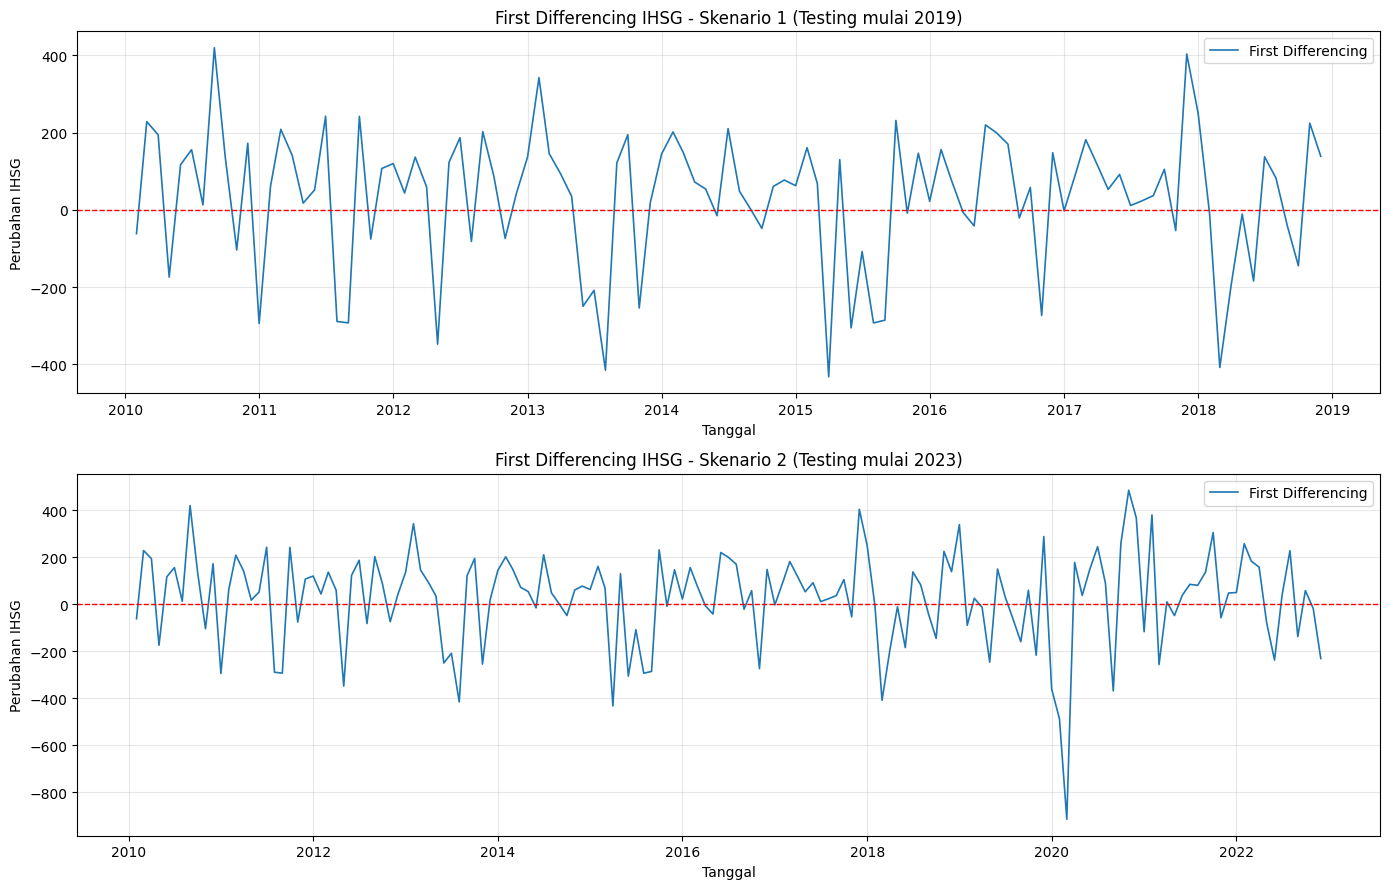

In [25]:

# ============================================================
# PLOT FIRST DIFFERENCING IHSG - DUA SKENARIO
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

for ax, (nama, bagian) in zip(axes, hasil_split.items()):

    # Mengambil data training
    train = bagian["train"].dropna()

    # Differencing pertama
    train_diff1 = train.diff().dropna()

    # Plot hasil differencing
    ax.plot(
        train_diff1.index,
        train_diff1.values,
        linewidth=1.2,
        label="First Differencing"
    )

    # Garis nol sebagai referensi
    ax.axhline(
        y=0,
        color="red",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(f"First Differencing IHSG - {nama}")
    ax.set_xlabel("Tanggal")
    ax.set_ylabel("Perubahan IHSG")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


- ACF PACF Setelah differencing 1

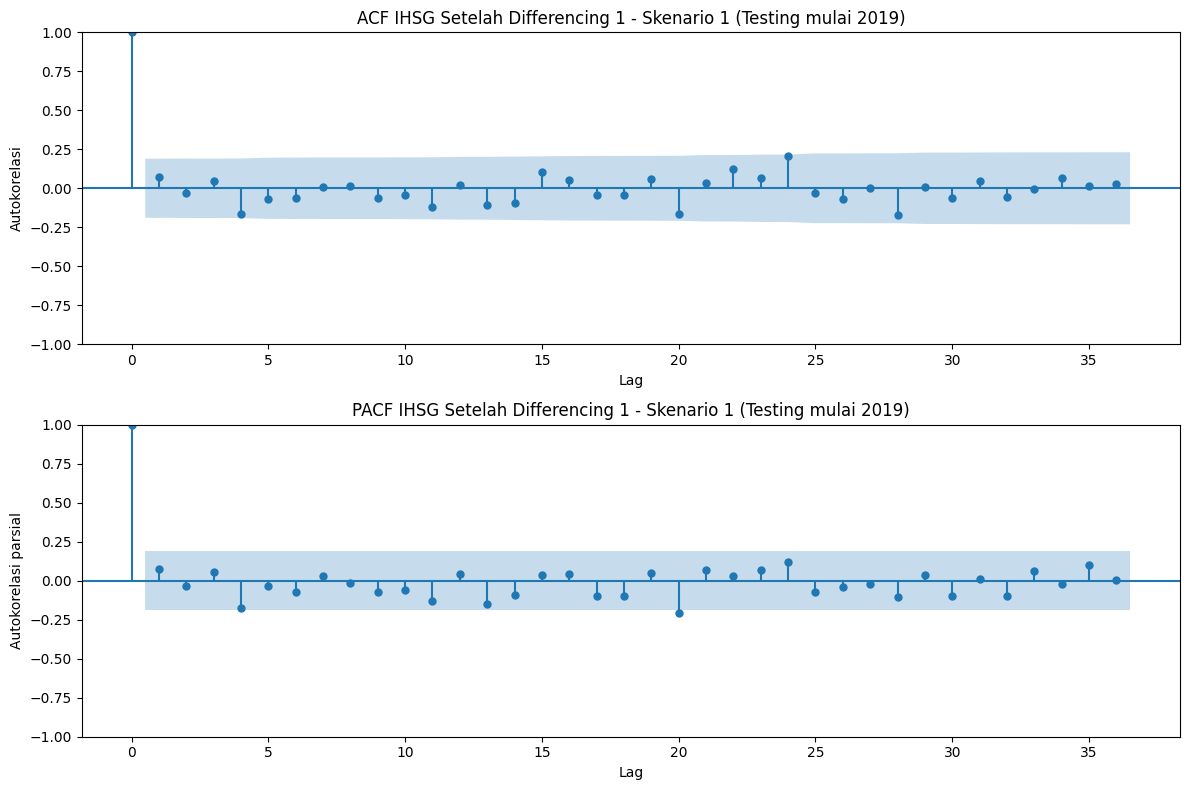

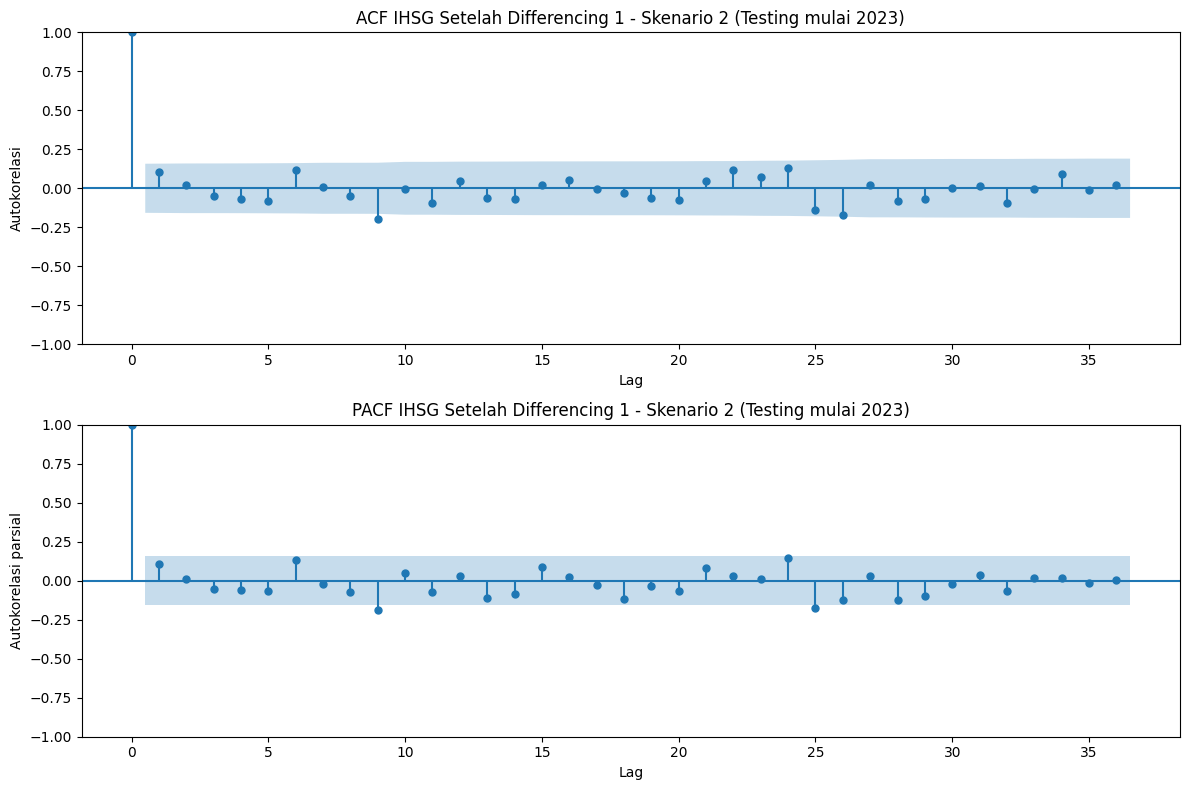

In [26]:

# ============================================================
# ACF DAN PACF SETELAH FIRST DIFFERENCING
# UNTUK DUA SKENARIO TRAINING
# ============================================================

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

for nama, bagian in hasil_split.items():

    # Mengambil data training
    train = bagian["train"].dropna()

    # First differencing
    train_diff1 = train.diff().dropna()

    # Menentukan jumlah lag
    jumlah_lag = min(36, len(train_diff1) // 2 - 1)

    # Membuat plot ACF dan PACF
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    plot_acf(
        train_diff1,
        lags=jumlah_lag,
        ax=axes[0],
        alpha=0.05
    )
    axes[0].set_title(
        f"ACF IHSG Setelah Differencing 1 - {nama}"
    )
    axes[0].set_xlabel("Lag")
    axes[0].set_ylabel("Autokorelasi")

    plot_pacf(
        train_diff1,
        lags=jumlah_lag,
        ax=axes[1],
        method="ywm",
        alpha=0.05
    )
    axes[1].set_title(
        f"PACF IHSG Setelah Differencing 1 - {nama}"
    )
    axes[1].set_xlabel("Lag")
    axes[1].set_ylabel("Autokorelasi parsial")

    plt.tight_layout()
    plt.show()


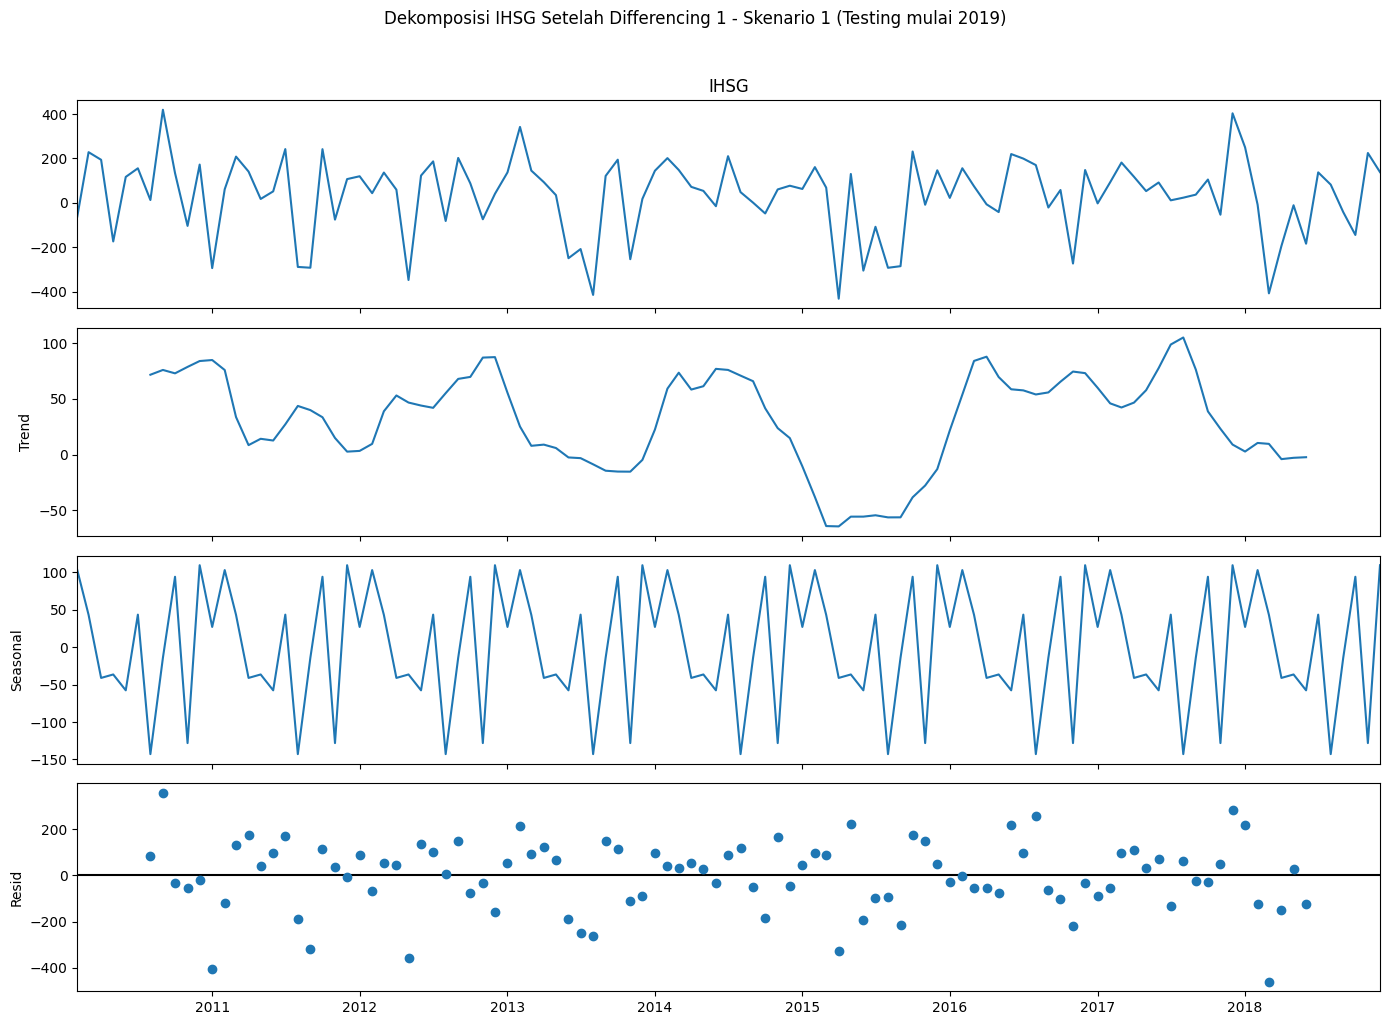

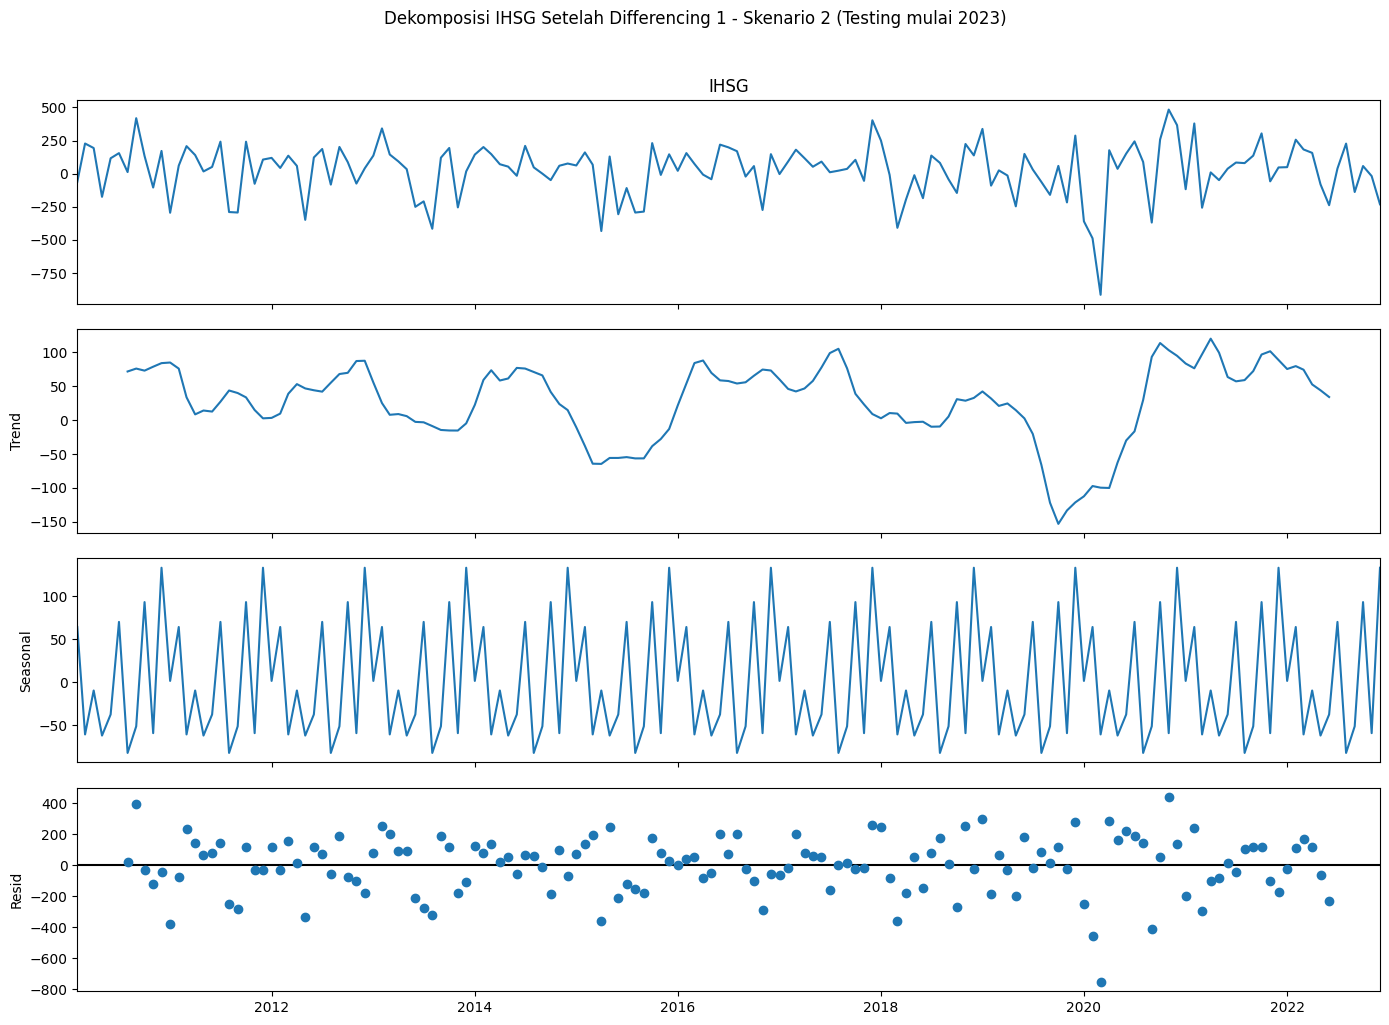

In [27]:

# ============================================================
# DEKOMPOSISI SEASONAL SETELAH DIFFERENCING 1
# UNTUK DUA SKENARIO
# ============================================================

import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

for nama, bagian in hasil_split.items():

    train = bagian["train"].dropna()

    # First differencing
    train_diff1 = train.diff().dropna()

    # Pastikan indeks bulanan teratur
    train_diff1 = train_diff1.asfreq("MS")

    if train_diff1.isna().any():
        print(
            f"{nama}: terdapat bulan yang hilang. "
            "Periksa kelengkapan data sebelum dekomposisi."
        )
        continue

    # Dekomposisi dengan periode musiman 12 bulan
    dekomposisi = seasonal_decompose(
        train_diff1,
        model="additive",
        period=12
    )

    fig = dekomposisi.plot()
    fig.set_size_inches(14, 10)
    fig.suptitle(
        f"Dekomposisi IHSG Setelah Differencing 1 - {nama}",
        y=1.02
    )

    plt.tight_layout()
    plt.show()


In [28]:

# ============================================================
# UJI LJUNG-BOX PADA FIRST DIFFERENCING
# SKENARIO 1 DAN SKENARIO 2
# ============================================================

import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox

for nama, bagian in hasil_split.items():

    # Mengambil data training
    train = bagian["train"].dropna()

    # First differencing
    train_diff1 = train.diff().dropna()

    print("\n" + "=" * 65)
    print(nama, "- UJI LJUNG-BOX FIRST DIFFERENCING")
    print("=" * 65)

    # Uji Ljung-Box pada lag 12, 24, dan 36
    hasil_lb = acorr_ljungbox(
        train_diff1,
        lags=[12, 24, 36],
        return_df=True
    )

    display(hasil_lb)

    # Interpretasi berdasarkan p-value
    for lag, baris in hasil_lb.iterrows():

        p_value = baris["lb_pvalue"]

        print(f"\nLag {lag}")
        print(f"p-value: {p_value:.6f}")

        if p_value < 0.05:
            print(
                "Kesimpulan: Tolak H0. "
                "Terdapat autokorelasi yang signifikan "
                "secara bersama-sama hingga lag tersebut."
            )
        else:
            print(
                "Kesimpulan: Belum cukup bukti menolak H0. "
                "Tidak ditemukan autokorelasi yang signifikan "
                "secara bersama-sama hingga lag tersebut."
            )



Skenario 1 (Testing mulai 2019) - UJI LJUNG-BOX FIRST DIFFERENCING


,lb_stat,lb_pvalue
12,7.565335,0.818109
24,25.067672,0.402091
36,32.381590,0.641428



Lag 12
p-value: 0.818109
Kesimpulan: Belum cukup bukti menolak H0. Tidak ditemukan autokorelasi yang signifikan secara bersama-sama hingga lag tersebut.

Lag 24
p-value: 0.402091
Kesimpulan: Belum cukup bukti menolak H0. Tidak ditemukan autokorelasi yang signifikan secara bersama-sama hingga lag tersebut.

Lag 36
p-value: 0.641428
Kesimpulan: Belum cukup bukti menolak H0. Tidak ditemukan autokorelasi yang signifikan secara bersama-sama hingga lag tersebut.

Skenario 2 (Testing mulai 2023) - UJI LJUNG-BOX FIRST DIFFERENCING


,lb_stat,lb_pvalue
12,14.948788,0.244249
24,25.964159,0.354986
36,40.922406,0.263232



Lag 12
p-value: 0.244249
Kesimpulan: Belum cukup bukti menolak H0. Tidak ditemukan autokorelasi yang signifikan secara bersama-sama hingga lag tersebut.

Lag 24
p-value: 0.354986
Kesimpulan: Belum cukup bukti menolak H0. Tidak ditemukan autokorelasi yang signifikan secara bersama-sama hingga lag tersebut.

Lag 36
p-value: 0.263232
Kesimpulan: Belum cukup bukti menolak H0. Tidak ditemukan autokorelasi yang signifikan secara bersama-sama hingga lag tersebut.


In [29]:

# Memeriksa autokorelasi lag 1 setelah differencing pertama

from statsmodels.tsa.stattools import acf

for nama, bagian in hasil_split.items():

    train = bagian["train"].dropna()
    train_diff1 = train.diff().dropna()

    nilai_acf = acf(train_diff1, nlags=3, fft=False)

    print("\n", nama)
    print("ACF lag 1:", round(nilai_acf[1], 4))
    print("ACF lag 2:", round(nilai_acf[2], 4))
    print("ACF lag 3:", round(nilai_acf[3], 4))



 Skenario 1 (Testing mulai 2019)
ACF lag 1: 0.0742
ACF lag 2: -0.0307
ACF lag 3: 0.0489

 Skenario 2 (Testing mulai 2023)
ACF lag 1: 0.1063
ACF lag 2: 0.0224
ACF lag 3: -0.0502


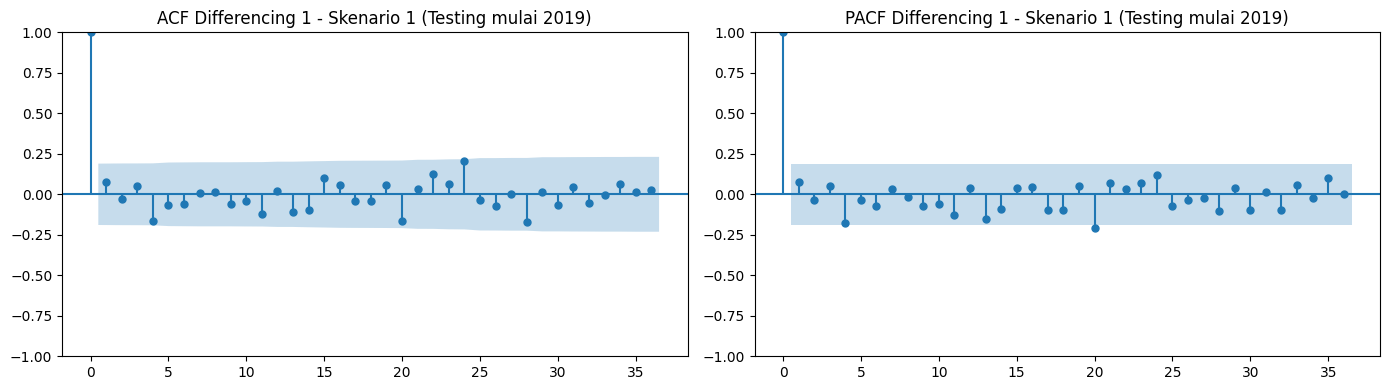

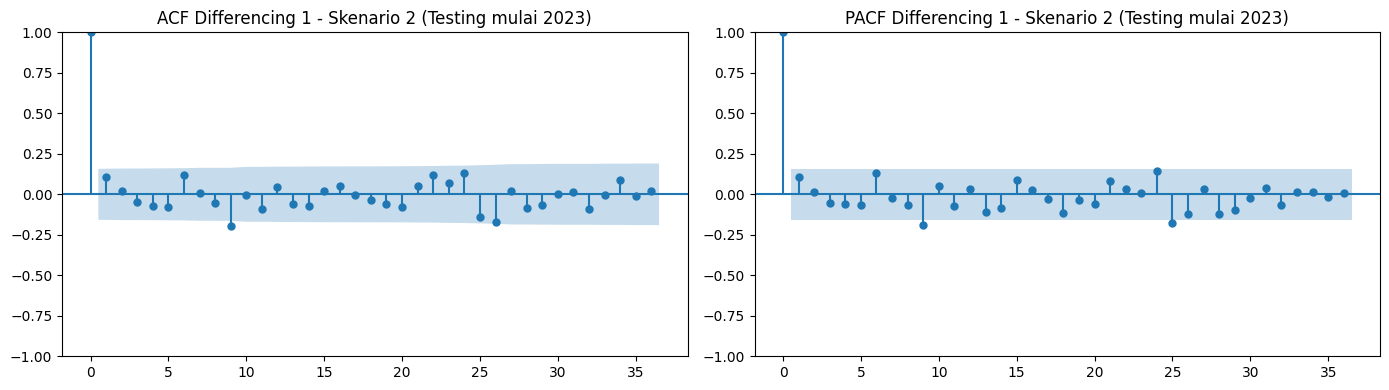

In [30]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

for nama, bagian in hasil_split.items():
    train = bagian["train"].dropna()
    train_diff1 = train.diff().dropna()

    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    plot_acf(
        train_diff1,
        lags=36,
        alpha=0.05,
        ax=ax[0]
    )
    ax[0].set_title(f"ACF Differencing 1 - {nama}")

    plot_pacf(
        train_diff1,
        lags=36,
        alpha=0.05,
        method="ywm",
        ax=ax[1]
    )
    ax[1].set_title(f"PACF Differencing 1 - {nama}")

    plt.tight_layout()
    plt.show()

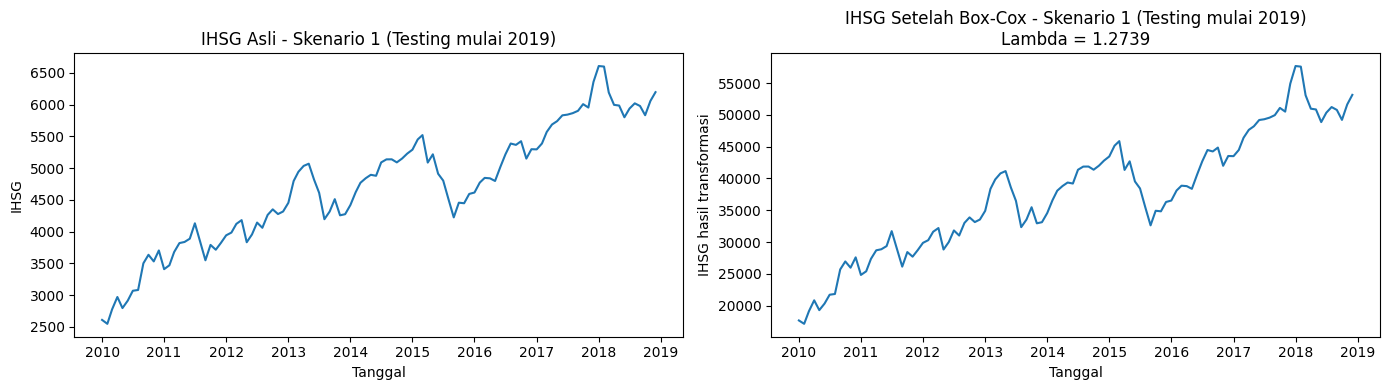


Skenario 1 (Testing mulai 2019)
Lambda Box-Cox: 1.2739

ADF - Box-Cox sebelum differencing
ADF statistic: -1.446169345941223
p-value: 0.5599529291046526

KPSS - Box-Cox sebelum differencing
KPSS statistic: 1.4718802980669323
p-value: 0.01

ADF - Box-Cox + differencing pertama
ADF statistic: -9.31886040743544
p-value: 1.0018404151860353e-15

KPSS - Box-Cox + differencing pertama
KPSS statistic: 0.058652373846474794
p-value: 0.1


/tmp/ipykernel_1784/4137221794.py:67: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF statistic:", adfuller(train_bc)[0])
/tmp/ipykernel_1784/4137221794.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("p-value:", adfuller(train_bc)[1])
/tmp/ipykernel_1784/4137221794.py:71: InterpolationWarning: The test statistic is outside of the range of p-values ava

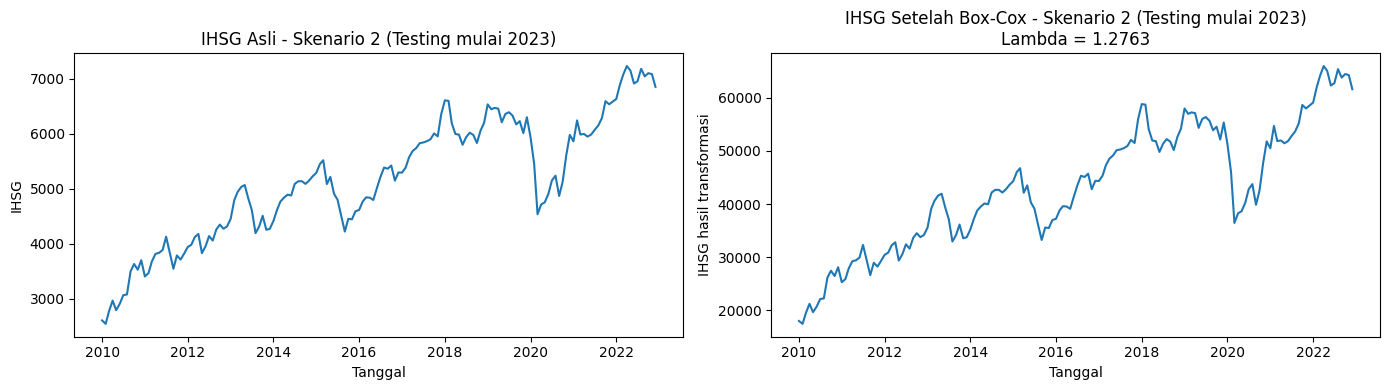


Skenario 2 (Testing mulai 2023)
Lambda Box-Cox: 1.2763

ADF - Box-Cox sebelum differencing
ADF statistic: -1.8312429199698972
p-value: 0.3650644412315065

KPSS - Box-Cox sebelum differencing
KPSS statistic: 1.5770896572744326
p-value: 0.01

ADF - Box-Cox + differencing pertama
ADF statistic: -10.92339119945675
p-value: 1.0245102647053301e-19

KPSS - Box-Cox + differencing pertama
KPSS statistic: 0.06198003544525553
p-value: 0.1


/tmp/ipykernel_1784/4137221794.py:67: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ADF statistic:", adfuller(train_bc)[0])
/tmp/ipykernel_1784/4137221794.py:68: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("p-value:", adfuller(train_bc)[1])
/tmp/ipykernel_1784/4137221794.py:71: InterpolationWarning: The test statistic is outside of the range of p-values ava

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from scipy.special import boxcox as boxcox_transform
from statsmodels.tsa.stattools import adfuller, kpss

hasil_boxcox = {}

for nama, bagian in hasil_split.items():

    # Ambil data training dan testing
    train = bagian["train"].dropna().astype(float)
    test = bagian["test"].dropna().astype(float)

    # Box-Cox memerlukan nilai positif
    if (train <= 0).any() or (test <= 0).any():
        raise ValueError(
            f"{nama}: Box-Cox membutuhkan seluruh nilai positif."
        )

    # Estimasi lambda hanya dari data training
    train_bc, lambda_bc = boxcox(train.values)

    # Terapkan lambda training yang sama pada testing
    test_bc = boxcox_transform(test.values, lambda_bc)

    # Simpan hasil transformasi
    train_bc = pd.Series(
        train_bc, index=train.index, name="IHSG_BoxCox"
    )
    test_bc = pd.Series(
        test_bc, index=test.index, name="IHSG_BoxCox"
    )

    hasil_boxcox[nama] = {
        "train": train_bc,
        "test": test_bc,
        "lambda": lambda_bc
    }

    # Grafik perbandingan level
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    ax[0].plot(train.index, train.values)
    ax[0].set_title(f"IHSG Asli - {nama}")
    ax[0].set_xlabel("Tanggal")
    ax[0].set_ylabel("IHSG")

    ax[1].plot(train_bc.index, train_bc.values)
    ax[1].set_title(
        f"IHSG Setelah Box-Cox - {nama}\n"
        f"Lambda = {lambda_bc:.4f}"
    )
    ax[1].set_xlabel("Tanggal")
    ax[1].set_ylabel("IHSG hasil transformasi")

    plt.tight_layout()
    plt.show()

    print(f"\n{nama}")
    print(f"Lambda Box-Cox: {lambda_bc:.4f}")

    # Uji stasioneritas level setelah Box-Cox
    print("\nADF - Box-Cox sebelum differencing")
    print("ADF statistic:", adfuller(train_bc)[0])
    print("p-value:", adfuller(train_bc)[1])

    print("\nKPSS - Box-Cox sebelum differencing")
    hasil_kpss = kpss(train_bc, regression="c", nlags="auto")
    print("KPSS statistic:", hasil_kpss[0])
    print("p-value:", hasil_kpss[1])

    # Differencing pertama setelah Box-Cox
    train_bc_diff1 = train_bc.diff().dropna()

    print("\nADF - Box-Cox + differencing pertama")
    hasil_adf_diff = adfuller(train_bc_diff1)
    print("ADF statistic:", hasil_adf_diff[0])
    print("p-value:", hasil_adf_diff[1])

    print("\nKPSS - Box-Cox + differencing pertama")
    hasil_kpss_diff = kpss(
        train_bc_diff1, regression="c", nlags="auto"
    )
    print("KPSS statistic:", hasil_kpss_diff[0])
    print("p-value:", hasil_kpss_diff[1])

In [33]:

import warnings
import itertools
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")

# ============================================================
# 1. MENYIAPKAN KANDIDAT SARIMA
# ============================================================

# Orde nonmusiman: (p, d, q)
p_values = range(0, 3)
d_values = [1]
q_values = range(0, 3)

# Orde musiman: (P, D, Q, s)
P_values = range(0, 2)
D_values = [0, 1]
Q_values = range(0, 2)
s = 12  # Data bulanan

orders = list(itertools.product(p_values, d_values, q_values))
seasonal_orders = [
    (P, D, Q, s)
    for P, D, Q in itertools.product(
        P_values, D_values, Q_values
    )
]

# ============================================================
# 2. FUNGSI PEMODELAN DAN EVALUASI
# ============================================================

def evaluasi_sarima(train, test):

    train = train.dropna().astype(float)
    test = test.dropna().astype(float)

    hasil_model = []
    model_terbaik = None
    aic_terbaik = np.inf
    orde_terbaik = None
    musiman_terbaik = None

    # Pilih model berdasarkan AIC training
    for order in orders:
        for seasonal_order in seasonal_orders:
            try:
                model = SARIMAX(
                    train,
                    order=order,
                    seasonal_order=seasonal_order,
                    trend="n",
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )

                hasil = model.fit(disp=False)

                hasil_model.append({
                    "order": order,
                    "seasonal_order": seasonal_order,
                    "AIC": hasil.aic,
                    "BIC": hasil.bic
                })

                if np.isfinite(hasil.aic) and hasil.aic < aic_terbaik:
                    aic_terbaik = hasil.aic
                    model_terbaik = hasil
                    orde_terbaik = order
                    musiman_terbaik = seasonal_order

            except Exception:
                continue

    if model_terbaik is None:
        raise RuntimeError(
            "Tidak ada model SARIMA yang berhasil diestimasi."
        )

    # Ramalan sepanjang periode testing
    prediksi = model_terbaik.get_forecast(
        steps=len(test)
    ).predicted_mean

    prediksi = np.asarray(prediksi)
    aktual = test.to_numpy()

    rmse = np.sqrt(mean_squared_error(aktual, prediksi))
    mae = mean_absolute_error(aktual, prediksi)

    # IHSG positif, sehingga MAPE dapat dihitung
    mape = np.mean(
        np.abs((aktual - prediksi) / aktual)
    ) * 100

    tabel_model = pd.DataFrame(hasil_model).sort_values(
        "AIC"
    ).reset_index(drop=True)

    return {
        "order": orde_terbaik,
        "seasonal_order": musiman_terbaik,
        "AIC": aic_terbaik,
        "BIC": model_terbaik.bic,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "aktual": aktual,
        "prediksi": prediksi,
        "model": model_terbaik,
        "peringkat_model": tabel_model
    }


# ============================================================
# 3. JALANKAN UNTUK KEDUA SKENARIO
# ============================================================

hasil_sarima = {}

for nama, bagian in hasil_split.items():

    print("\n" + "=" * 70)
    print(nama)
    print("=" * 70)

    train = bagian["train"]
    test = bagian["test"]

    hasil = evaluasi_sarima(train, test)
    hasil_sarima[nama] = hasil

    print("Orde SARIMA terbaik:", hasil["order"])
    print("Orde musiman terbaik:", hasil["seasonal_order"])
    print(f"AIC training : {hasil['AIC']:.3f}")
    print(f"BIC training : {hasil['BIC']:.3f}")
    print(f"RMSE testing : {hasil['RMSE']:.3f}")
    print(f"MAE testing  : {hasil['MAE']:.3f}")
    print(f"MAPE testing : {hasil['MAPE']:.3f}%")

    print("\nLima model teratas berdasarkan AIC:")
    print(hasil["peringkat_model"].head(5).to_string(index=False))


# ============================================================
# 4. RINGKASAN PERBANDINGAN DUA SKENARIO
# ============================================================

ringkasan = pd.DataFrame([
    {
        "Skenario": nama,
        "SARIMA": str(hasil["order"]),
        "Musiman": str(hasil["seasonal_order"]),
        "AIC": hasil["AIC"],
        "RMSE Testing": hasil["RMSE"],
        "MAE Testing": hasil["MAE"],
        "MAPE Testing (%)": hasil["MAPE"]
    }
    for nama, hasil in hasil_sarima.items()
])

print("\nRINGKASAN HASIL SARIMA")
display(ringkasan)



Skenario 1 (Testing mulai 2019)
Orde SARIMA terbaik: (1, 1, 2)
Orde musiman terbaik: (0, 1, 1, 12)
AIC training : 1065.971
BIC training : 1077.881
RMSE testing : 813.098
MAE testing  : 637.038
MAPE testing : 10.516%

Lima model teratas berdasarkan AIC:
    order seasonal_order         AIC         BIC
(1, 1, 2)  (0, 1, 1, 12) 1065.971010 1077.881143
(0, 1, 2)  (1, 1, 1, 12) 1066.331452 1078.241585
(2, 1, 2)  (1, 1, 1, 12) 1066.332423 1083.006609
(0, 1, 2)  (0, 1, 1, 12) 1067.461692 1076.989799
(1, 1, 2)  (1, 1, 1, 12) 1068.333396 1082.625556

Skenario 2 (Testing mulai 2023)
Orde SARIMA terbaik: (1, 1, 2)
Orde musiman terbaik: (0, 1, 1, 12)
AIC training : 1741.817
BIC training : 1756.077
RMSE testing : 450.580
MAE testing  : 319.625
MAPE testing : 4.315%

Lima model teratas berdasarkan AIC:
    order seasonal_order         AIC         BIC
(1, 1, 2)  (0, 1, 1, 12) 1741.816596 1756.076748
(0, 1, 2)  (0, 1, 1, 12) 1742.391973 1753.800094
(1, 1, 2)  (1, 1, 1, 12) 1742.744225 1759.856406
(0,

,Skenario,SARIMA,Musiman,AIC,RMSE Testing,MAE Testing,MAPE Testing (%)
0,Skenario 1 (Testing mulai 2019),"(1, 1, 2)","(0, 1, 1, 12)",1065.971010,813.097673,637.038231,10.516017
1,Skenario 2 (Testing mulai 2023),"(1, 1, 2)","(0, 1, 1, 12)",1741.816596,450.580372,319.625398,4.314769
